# Objective Quest DATAQUEST 5.0 — V1 Ordinal Tabular Baseline

**Goal:** predict `life_satisfaction` (1–4) and maximize **Quadratic Weighted Kappa (QWK)**.

This notebook is deliberately built around the dataset audit rather than a generic tabular recipe:

- **Ordinal regression**, not ordinary multiclass argmax.
- Preserve native missing values for XGBoost / LightGBM / CatBoost.
- Group-aware CV because exact duplicate respondent rows share the same `id`.
- Conservative **redundancy-aware repair** learned inside each training fold.
- Keep suspicious survey sentinel values as raw values **plus indicators**, instead of blind clipping/dropping.
- Curated semantic aggregates only; no brute-force feature explosion.
- No scaling, SMOTE, generic median imputation, or survey-weight sample weighting.
- Continuous 3-model ensemble, then optimize three ordinal thresholds for QWK.
- Submission IDs always come from `sample_submission.csv`, never from `test_final.id`.

### Kaggle runtime
Recommended accelerator: **GPU T4 x2**. CatBoost will try both GPUs (`0:1`), XGBoost will use CUDA, and LightGBM will try GPU with an automatic CPU fallback because Kaggle LightGBM GPU support can vary by image.

> This is V1: a strong, explainable baseline and trustworthy OOF framework before aggressive tuning/pseudo-labeling/target encoding.

> Note: CatBoost GPU training can be non-bit-deterministic due to floating-point reduction order. Seeds are fixed, but tiny rerun differences are still possible on GPU.


## 0. Setup & Imports


In [1]:
import os
import gc
import json
import random
import warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import ks_2samp

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import cohen_kappa_score, mean_squared_error

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

try:
    import shap
    HAS_SHAP = True
except Exception as e:
    HAS_SHAP = False
    print("SHAP unavailable; gain + permutation importance will still run:", e)


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

seed_everything(42)
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
sns.set_context("notebook")
print("Environment ready")
print("LightGBM:", lgb.__version__)
print("XGBoost:", xgb.__version__)


Environment ready
LightGBM: 4.6.0
XGBoost: 3.2.0


## 1. Problem Understanding & Config

QWK is ordinal: predicting 2 instead of 1 is less harmful than predicting 4 instead of 1. Therefore each booster learns a **continuous latent satisfaction score** using regression, and only after blending do we convert that score into classes 1–4 using three calibrated cut points.

The configuration intentionally avoids generic tabular defaults that are not appropriate here.


In [2]:
class CFG:
    COMPETITION_NAME = "Objective Quest DATAQUEST 5.0"
    VERSION = "v1"

    TRAIN_FILE = "train_final.csv"
    TEST_FILE = "test_final.csv"
    DICT_FILE = "data_dictionary.csv"
    SAMPLE_FILE = "sample_submission.csv"

    TARGET = "life_satisfaction"
    ID_COL = "id"
    HOUSEHOLD_COL = "household_id"

    OUTPUT_DIR = Path("/kaggle/working/oqdq5_v1") if Path("/kaggle/working").exists() else Path("./oqdq5_v1")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    SEED = 42
    N_FOLDS = 5

    # Explainability probe
    PROBE_N_ESTIMATORS = 2500
    PROBE_EARLY_STOPPING = 150
    SHAP_SAMPLE = 4000
    PERM_TOP_N = 25

    # Feature selection informed by the probe + prior dataset audit.
    TOP_N_PROBE_FEATURES = 120

    # Final models
    LGB_N_ESTIMATORS = 7000
    XGB_N_ESTIMATORS = 7000
    CAT_ITERATIONS = 7000
    LEARNING_RATE = 0.025
    EARLY_STOPPING = 250
    VERBOSE = 250

    # Use Kaggle GPUs when possible.
    USE_GPU = True
    CAT_DEVICES = "0:1"

    # Blend optimization guardrail.
    BLEND_RANDOM_CANDIDATES = 300
    BLEND_TOP_K_REFINE = 10
    MIN_BLEND_GAIN = 0.0015

    # Conservative redundancy mapping threshold.
    REPAIR_MIN_ACCURACY = 0.995
    REPAIR_MIN_SUPPORT = 100

    # No scaling, no oversampling, no generic missing imputation.
    USE_SCALING = False
    USE_OVERSAMPLING = False
    USE_GENERIC_IMPUTATION = False

print(vars(CFG))


{'__module__': '__main__', 'COMPETITION_NAME': 'Objective Quest DATAQUEST 5.0', 'VERSION': 'v1', 'TRAIN_FILE': 'train_final.csv', 'TEST_FILE': 'test_final.csv', 'DICT_FILE': 'data_dictionary.csv', 'SAMPLE_FILE': 'sample_submission.csv', 'TARGET': 'life_satisfaction', 'ID_COL': 'id', 'HOUSEHOLD_COL': 'household_id', 'OUTPUT_DIR': PosixPath('/kaggle/working/oqdq5_v1'), 'SEED': 42, 'N_FOLDS': 5, 'PROBE_N_ESTIMATORS': 2500, 'PROBE_EARLY_STOPPING': 150, 'SHAP_SAMPLE': 4000, 'PERM_TOP_N': 25, 'TOP_N_PROBE_FEATURES': 120, 'LGB_N_ESTIMATORS': 7000, 'XGB_N_ESTIMATORS': 7000, 'CAT_ITERATIONS': 7000, 'LEARNING_RATE': 0.025, 'EARLY_STOPPING': 250, 'VERBOSE': 250, 'USE_GPU': True, 'CAT_DEVICES': '0:1', 'BLEND_RANDOM_CANDIDATES': 300, 'BLEND_TOP_K_REFINE': 10, 'MIN_BLEND_GAIN': 0.0015, 'REPAIR_MIN_ACCURACY': 0.995, 'REPAIR_MIN_SUPPORT': 100, 'USE_SCALING': False, 'USE_OVERSAMPLING': False, 'USE_GENERIC_IMPUTATION': False, '__dict__': <attribute '__dict__' of 'CFG' objects>, '__weakref__': <attribute

### 1.1 Auto-discover the Kaggle dataset

The competition/input slug can differ between Kaggle notebooks, so the notebook searches for a directory containing all four required files.


In [3]:
def discover_data_dir():
    required = {CFG.TRAIN_FILE, CFG.TEST_FILE, CFG.DICT_FILE, CFG.SAMPLE_FILE}
    roots = [Path("/kaggle/input"), Path("."), Path("./data")]

    candidates = []
    for root in roots:
        if not root.exists():
            continue
        try:
            for train_path in root.rglob(CFG.TRAIN_FILE):
                folder = train_path.parent
                present = {p.name for p in folder.iterdir() if p.is_file()}
                if required.issubset(present):
                    candidates.append(folder)
        except PermissionError:
            continue

    if not candidates:
        raise FileNotFoundError(
            f"Could not find a folder containing {sorted(required)}. "
            "Attach the Objective Quest DATAQUEST 5.0 dataset to this Kaggle notebook."
        )

    # Prefer /kaggle/input and the shortest path.
    candidates = sorted(set(candidates), key=lambda p: (0 if str(p).startswith('/kaggle/input') else 1, len(str(p))))
    return candidates[0]

DATA_DIR = discover_data_dir()
TRAIN_PATH = DATA_DIR / CFG.TRAIN_FILE
TEST_PATH = DATA_DIR / CFG.TEST_FILE
DICT_PATH = DATA_DIR / CFG.DICT_FILE
SAMPLE_PATH = DATA_DIR / CFG.SAMPLE_FILE

print("DATA_DIR:", DATA_DIR)
print("TRAIN_PATH:", TRAIN_PATH)


DATA_DIR: /kaggle/input/competitions/oq-dq-5
TRAIN_PATH: /kaggle/input/competitions/oq-dq-5/train_final.csv


## 2. Preprocessing

This section performs integrity checks and defines fold-safe preprocessing. It **does not** scale values or globally fill NaNs.


In [4]:
train = pd.read_csv(TRAIN_PATH, low_memory=False)
test = pd.read_csv(TEST_PATH, low_memory=False)
data_dictionary = pd.read_csv(DICT_PATH)
sample_submission = pd.read_csv(SAMPLE_PATH)

assert CFG.TARGET in train.columns
assert CFG.TARGET not in test.columns
assert len(train) == 95609, f"Unexpected train rows: {len(train)}"
assert len(test) == 23902, f"Unexpected test rows: {len(test)}"
assert len(sample_submission) == len(test)

print("train:", train.shape)
print("test:", test.shape)
print("dictionary:", data_dictionary.shape)
print("sample submission:", sample_submission.shape)
print("target values:", sorted(train[CFG.TARGET].dropna().unique().tolist()))


train: (95609, 179)
test: (23902, 178)
dictionary: (187, 3)
sample submission: (23902, 2)
target values: [1, 2, 3, 4]


### 2.1 Integrity audit: duplicates, IDs, dictionary mismatch, submission alignment

Two dataset-specific hazards are checked explicitly:

1. `id` is not unique and duplicated IDs correspond to duplicate rows, so random CV can leak identical records across folds.
2. `sample_submission.id` is a competition row identifier and is **not** the same sequence as `test_final.id`. The sample IDs must be preserved exactly.


In [5]:
def integrity_audit(train_df, test_df, sample_df, dictionary_df):
    report = {}
    report["train_rows"] = len(train_df)
    report["test_rows"] = len(test_df)
    report["train_unique_id"] = train_df[CFG.ID_COL].nunique(dropna=False)
    report["test_unique_id"] = test_df[CFG.ID_COL].nunique(dropna=False)
    report["train_duplicate_id_rows"] = int(train_df.duplicated(CFG.ID_COL, keep=False).sum())
    report["test_duplicate_id_rows"] = int(test_df.duplicated(CFG.ID_COL, keep=False).sum())
    report["train_exact_duplicate_rows"] = int(train_df.duplicated(keep=False).sum())
    report["test_exact_duplicate_rows"] = int(test_df.duplicated(keep=False).sum())
    report["sample_id_equals_test_id"] = bool(
        CFG.ID_COL in sample_df.columns and np.array_equal(sample_df[CFG.ID_COL].values, test_df[CFG.ID_COL].values)
    )

    dict_names = set(dictionary_df["kolom"].astype(str)) if "kolom" in dictionary_df.columns else set()
    train_feature_names = set(train_df.columns)
    report["dictionary_only_columns"] = sorted(dict_names - train_feature_names)
    report["train_columns_missing_from_dictionary"] = sorted(train_feature_names - dict_names - {CFG.TARGET})
    return report

audit = integrity_audit(train, test, sample_submission, data_dictionary)
display(pd.Series(audit, name="value").to_frame())

# Verify same-id train records do not disagree on the target.
id_target_nunique = train.groupby(CFG.ID_COL)[CFG.TARGET].nunique(dropna=False)
print("Duplicate IDs with conflicting targets:", int((id_target_nunique > 1).sum()))

# Submission guardrail.
assert not audit["sample_id_equals_test_id"], (
    "Dataset behavior changed: sample_submission.id unexpectedly equals test_final.id. "
    "Re-audit before changing submission logic."
)


,value
train_rows,95609
test_rows,23902
train_unique_id,94663
test_unique_id,23666
train_duplicate_id_rows,1892
test_duplicate_id_rows,472
train_exact_duplicate_rows,1892
test_exact_duplicate_rows,472
sample_id_equals_test_id,False
dictionary_only_columns,"[anxiety_screening_past_year, area_type, drink..."


Duplicate IDs with conflicting targets: 0


### 2.2 Target and grouped-CV strata

`id` is used only as a grouping key, never as a predictive feature. Stratification combines target and survey year so each fold remains representative across both outcome and collection period.


In [6]:
y = train[CFG.TARGET].astype(int).values
groups = train[CFG.ID_COL].astype(str).values

survey_year_for_strata = train["survey_year"].fillna(-1).astype(str) if "survey_year" in train.columns else pd.Series("NA", index=train.index)
strata = train[CFG.TARGET].astype(str) + "__yr_" + survey_year_for_strata

cv = StratifiedGroupKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
folds = list(cv.split(train, strata, groups=groups))

fold_rows = []
for fold, (tr_idx, va_idx) in enumerate(folds):
    overlap = set(groups[tr_idx]).intersection(set(groups[va_idx]))
    fold_rows.append({
        "fold": fold,
        "train_n": len(tr_idx),
        "valid_n": len(va_idx),
        "group_overlap": len(overlap),
        "valid_target_mean": float(np.mean(y[va_idx])),
    })

display(pd.DataFrame(fold_rows))
assert all(r["group_overlap"] == 0 for r in fold_rows)


,fold,train_n,valid_n,group_overlap,valid_target_mean
0,0,76485,19124,0,1.606672
1,1,76500,19109,0,1.605893
2,2,76487,19122,0,1.611024
3,3,76491,19118,0,1.604090
4,4,76473,19136,0,1.604776


### 2.3 Fold-safe redundancy-aware repair

Only high-confidence mappings are accepted. A mapping is learned from the **training portion of the fold** and then used only to fill missing destination values. Existing observed values are never overwritten.

This is fundamentally different from median imputation: it reconstructs information from a near-deterministic sibling feature.


In [7]:
REPAIR_PAIRS = [
    ("data_year", "survey_year"),
    ("survey_year", "data_year"),
    ("interview_month", "interview_quarter"),
    ("food_security_4cat", "food_security_3cat"),
    ("cancer_types_count", "cancer_ever"),
    ("ecigarette_status", "ever_used_ecigarette"),
    ("children_in_family", "children_in_household"),
    ("children_in_household", "children_in_family"),
    ("smoking_status", "ever_smoked"),
    ("health_insurance_type", "private_health_insurance"),
    ("marital_status_detailed", "marital_status"),
]

# Observed survey sentinel-like values identified in the dataset audit.
# Keep the raw values; add indicators rather than blindly clipping/removing them.
SPECIAL_CODES = {
    "weight_pounds": {996, 997, 999},
    "height_inches": {96, 97, 98, 99},
    "age": {97, 99},
    "hours_worked_per_week": {990},
    "days_missed_work": {997, 998, 999},
    "income_to_poverty_ratio": {110},
}


def learn_mode_mapping(df, src, dst, min_support=100):
    if src not in df.columns or dst not in df.columns:
        return None
    pairs = df[[src, dst]].dropna()
    if len(pairs) < min_support:
        return None

    mapping = pairs.groupby(src, dropna=False)[dst].agg(lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan).to_dict()
    pred = pairs[src].map(mapping)
    accuracy = float((pred.values == pairs[dst].values).mean())
    return {"mapping": mapping, "accuracy": accuracy, "support": len(pairs)}


class FoldPreprocessor:
    def __init__(self, min_accuracy=0.995, min_support=100):
        self.min_accuracy = min_accuracy
        self.min_support = min_support
        self.repair_rules_ = {}
        self.repair_report_ = None

    def fit(self, df):
        rows = []
        for src, dst in REPAIR_PAIRS:
            learned = learn_mode_mapping(df, src, dst, self.min_support)
            if learned is None:
                continue
            accepted = learned["accuracy"] >= self.min_accuracy
            rows.append({
                "source": src,
                "destination": dst,
                "accuracy": learned["accuracy"],
                "support": learned["support"],
                "accepted": accepted,
            })
            if accepted:
                self.repair_rules_[(src, dst)] = learned["mapping"]
        self.repair_report_ = pd.DataFrame(rows)
        return self

    def transform(self, df):
        out = df.copy()
        if CFG.TARGET in out.columns:
            out = out.drop(columns=[CFG.TARGET])

        # Preserve raw missingness signal before repair.
        feature_cols_for_missing = [c for c in out.columns if c not in [CFG.ID_COL, CFG.HOUSEHOLD_COL]]
        out["row_missing_count_raw"] = out[feature_cols_for_missing].isna().sum(axis=1).astype(np.int16)

        # Fill only missing destinations from accepted high-confidence sibling mappings.
        for (src, dst), mapping in self.repair_rules_.items():
            if src not in out.columns or dst not in out.columns:
                continue
            fill_mask = out[dst].isna() & out[src].notna()
            if fill_mask.any():
                inferred = out.loc[fill_mask, src].map(mapping)
                valid = inferred.notna()
                if valid.any():
                    idx = inferred.index[valid]
                    out.loc[idx, dst] = inferred.loc[idx]

        out["row_missing_count_after_repair"] = out[feature_cols_for_missing].isna().sum(axis=1).astype(np.int16)
        out["repaired_value_count"] = (out["row_missing_count_raw"] - out["row_missing_count_after_repair"]).clip(lower=0).astype(np.int16)

        # Sentinel indicators; raw columns remain untouched.
        sentinel_cols = []
        for col, values in SPECIAL_CODES.items():
            if col in out.columns:
                new_col = f"{col}__special_code"
                out[new_col] = out[col].isin(values).astype(np.int8)
                sentinel_cols.append(new_col)
        if sentinel_cols:
            out["special_code_count"] = out[sentinel_cols].sum(axis=1).astype(np.int8)

        return out

    def fit_transform(self, df):
        return self.fit(df).transform(df)


### 2.4 Audit the redundancy rules on the full training data

This cell is diagnostic only. Final CV later relearns these mappings inside each fold.


In [8]:
_audit_preprocessor = FoldPreprocessor(CFG.REPAIR_MIN_ACCURACY, CFG.REPAIR_MIN_SUPPORT).fit(train.drop(columns=[CFG.TARGET]))
display(_audit_preprocessor.repair_report_.sort_values(["accepted", "accuracy", "support"], ascending=[False, False, False]))


,source,destination,accuracy,support,accepted
0,data_year,survey_year,1.000000,80982,True
1,survey_year,data_year,1.000000,80982,True
2,interview_month,interview_quarter,1.000000,80922,True
4,cancer_types_count,cancer_ever,1.000000,80885,True
3,food_security_4cat,food_security_3cat,1.000000,80797,True
5,ecigarette_status,ever_used_ecigarette,0.999219,80681,True
6,children_in_family,children_in_household,0.998612,80720,True
7,children_in_household,children_in_family,0.998612,80720,True
8,smoking_status,ever_smoked,0.998495,81037,True
9,health_insurance_type,private_health_insurance,0.998177,54851,True


## 3. Fitting for Explainable AI

Before broad EDA, fit one **group-safe LightGBM regression probe**. Its job is not to be the final model. It identifies which variables deserve the most attention and creates a stable importance ranking for conservative feature selection.

Explainability layers:
1. native LightGBM gain importance,
2. SHAP mean absolute contribution (if available),
3. permutation **ΔQWK** for top candidates.


In [9]:
def qwk(y_true, y_pred_class):
    return float(cohen_kappa_score(np.asarray(y_true, dtype=int), np.asarray(y_pred_class, dtype=int), weights="quadratic"))


def apply_thresholds(pred, thresholds):
    thresholds = np.sort(np.asarray(thresholds, dtype=float))
    return np.digitize(np.asarray(pred, dtype=float), thresholds) + 1


def initial_thresholds_from_distribution(y_true, continuous_pred):
    y_true = np.asarray(y_true, dtype=int)
    continuous_pred = np.asarray(continuous_pred, dtype=float)
    props = np.array([(y_true <= k).mean() for k in [1, 2, 3]])
    props = np.clip(props, 0.01, 0.99)
    return np.quantile(continuous_pred, props)


def optimize_thresholds(y_true, continuous_pred, starts=None, maxiter=180):
    y_true = np.asarray(y_true, dtype=int)
    continuous_pred = np.asarray(continuous_pred, dtype=float)

    if starts is None:
        starts = [
            initial_thresholds_from_distribution(y_true, continuous_pred),
            np.array([1.55, 2.05, 2.55]),
            np.array([1.50, 2.50, 3.50]),
        ]

    lo = float(np.nanpercentile(continuous_pred, 0.1))
    hi = float(np.nanpercentile(continuous_pred, 99.9))
    if not np.isfinite(lo) or not np.isfinite(hi) or lo >= hi:
        lo, hi = 1.0, 4.0

    def loss(t):
        t = np.sort(np.asarray(t, dtype=float))
        # Avoid collapsed class intervals.
        if np.min(np.diff(t)) < 0.01:
            return 2.0
        return -qwk(y_true, apply_thresholds(continuous_pred, t))

    best_t, best_score = None, -np.inf
    for start in starts:
        start = np.clip(np.sort(np.asarray(start, dtype=float)), lo, hi)
        result = minimize(
            loss,
            x0=start,
            method="Powell",
            bounds=[(lo, hi)] * 3,
            options={"maxiter": maxiter, "xtol": 1e-4, "ftol": 1e-6, "disp": False},
        )
        t = np.sort(result.x)
        score = qwk(y_true, apply_thresholds(continuous_pred, t))
        if score > best_score:
            best_score = score
            best_t = t
    return np.asarray(best_t), float(best_score)


def model_feature_columns(df):
    return [c for c in df.columns if c not in [CFG.ID_COL, CFG.HOUSEHOLD_COL, CFG.TARGET]]

probe_train_idx, probe_valid_idx = folds[0]
probe_raw_train = train.iloc[probe_train_idx].drop(columns=[CFG.TARGET]).copy()
probe_raw_valid = train.iloc[probe_valid_idx].drop(columns=[CFG.TARGET]).copy()
probe_y_train = y[probe_train_idx]
probe_y_valid = y[probe_valid_idx]

probe_pre = FoldPreprocessor(CFG.REPAIR_MIN_ACCURACY, CFG.REPAIR_MIN_SUPPORT).fit(probe_raw_train)
probe_X_train_all = probe_pre.transform(probe_raw_train)
probe_X_valid_all = probe_pre.transform(probe_raw_valid)

probe_features = model_feature_columns(probe_X_train_all)
probe_X_train = probe_X_train_all[probe_features]
probe_X_valid = probe_X_valid_all[probe_features]

probe_model = lgb.LGBMRegressor(
    objective="regression_l2",
    n_estimators=CFG.PROBE_N_ESTIMATORS,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=40,
    subsample=0.90,
    subsample_freq=1,
    colsample_bytree=0.90,
    reg_alpha=0.05,
    reg_lambda=4.0,
    random_state=CFG.SEED,
    n_jobs=-1,
    verbosity=-1,
)

probe_model.fit(
    probe_X_train,
    probe_y_train,
    eval_set=[(probe_X_valid, probe_y_valid)],
    eval_metric="rmse",
    callbacks=[
        lgb.early_stopping(CFG.PROBE_EARLY_STOPPING, verbose=False),
        lgb.log_evaluation(CFG.VERBOSE),
    ],
)

probe_pred = probe_model.predict(probe_X_valid, num_iteration=probe_model.best_iteration_)
probe_thresholds, probe_qwk = optimize_thresholds(probe_y_valid, probe_pred)
probe_round_qwk = qwk(probe_y_valid, np.clip(np.rint(probe_pred), 1, 4).astype(int))
probe_rmse = mean_squared_error(probe_y_valid, probe_pred) ** 0.5

print("Probe best iteration:", probe_model.best_iteration_)
print("Probe RMSE:", round(probe_rmse, 6))
print("Probe naive-round QWK:", round(probe_round_qwk, 6))
print("Probe calibrated thresholds:", np.round(probe_thresholds, 5))
print("Probe calibrated QWK:", round(probe_qwk, 6))


[250]	valid_0's rmse: 0.513873	valid_0's l2: 0.264066
[500]	valid_0's rmse: 0.513575	valid_0's l2: 0.26376
Probe best iteration: 431
Probe RMSE: 0.51348
Probe naive-round QWK: 0.431211
Probe calibrated thresholds: [1.54896 2.00318 2.52204]
Probe calibrated QWK: 0.490875


,feature,gain,shap_mean_abs,permutation_qwk,permutation_delta_qwk,gain_rank_pct,shap_mean_abs_rank_pct,permutation_delta_qwk_rank_pct,explainability_score
0,general_health_status,0.277645,0.174578,0.381375,0.109500,1.000000,1.000000,1.000000,1.000000
1,depression_frequency,0.251917,0.125591,0.411348,0.079527,0.994624,0.994624,0.994624,0.994624
2,anxiety_frequency,0.050736,0.056110,0.478982,0.011893,0.989247,0.989247,0.983871,0.987634
3,marital_status,0.043524,0.055777,0.478324,0.012551,0.983871,0.983871,0.989247,0.985484
4,worry_about_medical_costs,0.018838,0.039423,0.482649,0.008226,0.967742,0.978495,0.978495,0.974731
5,difficulty_social_activities,0.024396,0.020526,0.486969,0.003906,0.978495,0.956989,0.962366,0.966129
6,marital_status_detailed,0.021162,0.029305,0.488319,0.002556,0.973118,0.973118,0.940860,0.963441
7,anxiety_level,0.011311,0.023227,0.486651,0.004223,0.951613,0.962366,0.973118,0.961828
8,income_to_poverty_ratio,0.016469,0.019044,0.486705,0.004170,0.962366,0.946237,0.967742,0.958333
9,difficulty_remembering,0.011737,0.020481,0.489074,0.001801,0.956989,0.951613,0.924731,0.945430


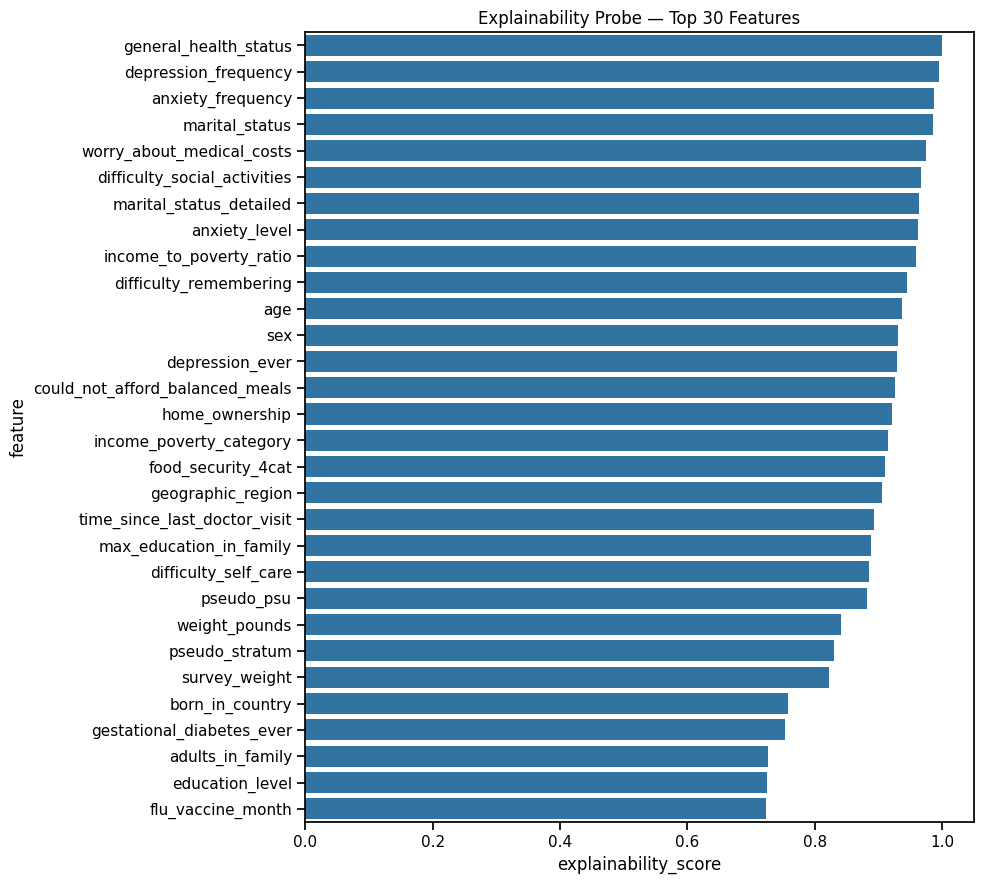

In [10]:
# 1) Gain importance
gain_df = pd.DataFrame({
    "feature": probe_features,
    "gain": probe_model.booster_.feature_importance(importance_type="gain"),
})
gain_df["gain"] = gain_df["gain"] / max(gain_df["gain"].sum(), 1e-12)

# 2) SHAP mean |value|
shap_df = pd.DataFrame(columns=["feature", "shap_mean_abs"])
if HAS_SHAP:
    rng = np.random.default_rng(CFG.SEED)
    n_shap = min(CFG.SHAP_SAMPLE, len(probe_X_valid))
    shap_idx = rng.choice(len(probe_X_valid), size=n_shap, replace=False)
    shap_sample = probe_X_valid.iloc[shap_idx]
    try:
        explainer = shap.TreeExplainer(probe_model)
        shap_values = explainer.shap_values(shap_sample)
        if isinstance(shap_values, list):
            shap_values = shap_values[0]
        shap_df = pd.DataFrame({
            "feature": probe_features,
            "shap_mean_abs": np.abs(np.asarray(shap_values)).mean(axis=0),
        })
        shap_df["shap_mean_abs"] /= max(shap_df["shap_mean_abs"].sum(), 1e-12)
    except Exception as e:
        print("SHAP calculation skipped:", e)

# 3) Permutation delta-QWK for the strongest gain candidates.
perm_candidates = gain_df.sort_values("gain", ascending=False).head(CFG.PERM_TOP_N)["feature"].tolist()
perm_rows = []
rng = np.random.default_rng(CFG.SEED + 123)
baseline_perm_qwk = qwk(probe_y_valid, apply_thresholds(probe_pred, probe_thresholds))

for feature in perm_candidates:
    X_perm = probe_X_valid.copy()
    values = X_perm[feature].to_numpy(copy=True)
    rng.shuffle(values)
    X_perm[feature] = values
    perm_pred = probe_model.predict(X_perm, num_iteration=probe_model.best_iteration_)
    perm_score = qwk(probe_y_valid, apply_thresholds(perm_pred, probe_thresholds))
    perm_rows.append({
        "feature": feature,
        "permutation_qwk": perm_score,
        "permutation_delta_qwk": baseline_perm_qwk - perm_score,
    })

perm_df = pd.DataFrame(perm_rows)

importance = gain_df.merge(shap_df, on="feature", how="left").merge(perm_df, on="feature", how="left")
importance["shap_mean_abs"] = importance["shap_mean_abs"].fillna(0.0)
importance["permutation_delta_qwk"] = importance["permutation_delta_qwk"].fillna(0.0)

# Rank aggregation: all components point in the same direction (higher = more important).
for col in ["gain", "shap_mean_abs", "permutation_delta_qwk"]:
    importance[f"{col}_rank_pct"] = importance[col].rank(pct=True, method="average")

importance["explainability_score"] = (
    0.35 * importance["gain_rank_pct"]
    + 0.35 * importance["shap_mean_abs_rank_pct"]
    + 0.30 * importance["permutation_delta_qwk_rank_pct"]
)
importance = importance.sort_values("explainability_score", ascending=False).reset_index(drop=True)
probe_top_features = importance.head(CFG.TOP_N_PROBE_FEATURES)["feature"].tolist()

display(importance.head(30))

plt.figure(figsize=(10, 9))
sns.barplot(data=importance.head(30), x="explainability_score", y="feature")
plt.title("Explainability Probe — Top 30 Features")
plt.tight_layout()
plt.show()


## 4. EDA

EDA is driven by the probe instead of treating all 178 columns equally. It focuses on:

- hidden structural issues and sentinel/outlier-like codes,
- missingness as signal,
- train/test drift,
- target relationships for important variables,
- pairwise interactions and correlations.


### 4.1 Target distribution and ordinal imbalance


,count,pct
life_satisfaction,,
1,42968,0.449414
2,48189,0.504022
3,3559,0.037225
4,893,0.009340


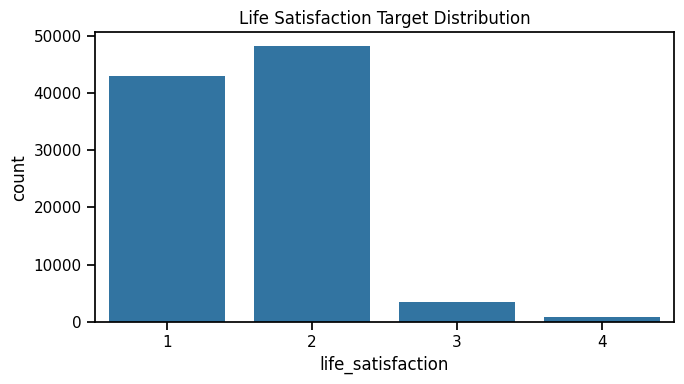

In [11]:
target_counts = train[CFG.TARGET].value_counts().sort_index()
target_dist = pd.DataFrame({
    "count": target_counts,
    "pct": target_counts / len(train),
})
display(target_dist)

plt.figure(figsize=(7, 4))
sns.countplot(data=train, x=CFG.TARGET, order=sorted(train[CFG.TARGET].unique()))
plt.title("Life Satisfaction Target Distribution")
plt.tight_layout()
plt.show()


### 4.2 Missingness is information, not just a cleaning problem


,mean,median,std,min,max
life_satisfaction,,,,,
1,24.592674,23.0,8.552539,5,59
2,25.689514,24.0,8.918938,4,60
3,28.923574,30.0,8.990489,6,55
4,29.791713,32.0,8.857318,9,52


,missing_rate
flu_vaccine_year,0.538485
flu_vaccine_month,0.534291
ever_married,0.521112
gestational_diabetes_ever,0.500152
works_full_time,0.485854
hours_worked_per_week,0.485080
insurance_marketplace_plan1,0.449884
days_missed_work,0.440147
has_paid_sick_leave,0.439645
employer_offers_insurance,0.439341


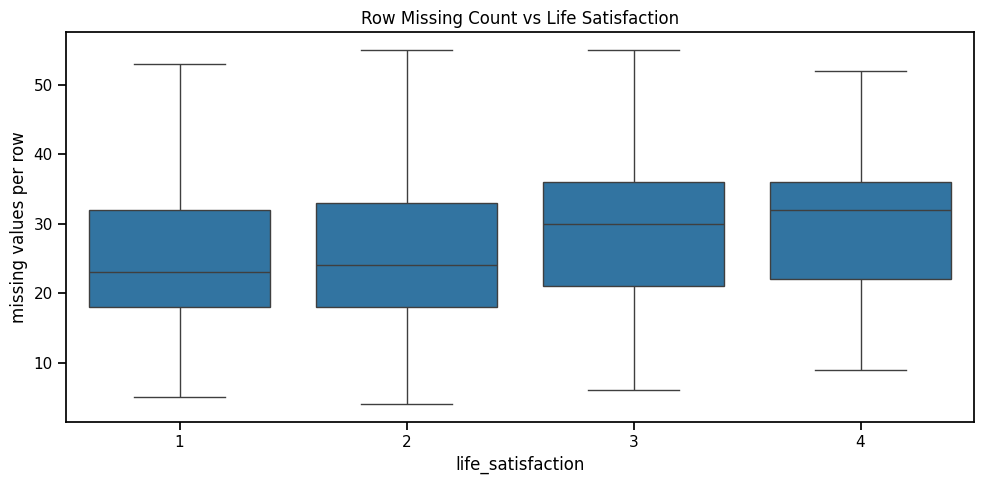

,feature,missing_rate,target_mean_present,target_mean_missing,abs_target_mean_gap
2,ever_married,0.521112,1.715044,1.506734,0.208310
24,anxiety_level,0.349946,1.673843,1.481380,0.192463
31,difficulty_walking_medium,0.168823,1.576056,1.756335,0.180279
34,difficulty_walking_short,0.164409,1.577782,1.752402,0.174620
30,takes_mental_health_medication,0.248690,1.564038,1.734744,0.170705
33,difficulty_climbing_steps,0.164639,1.578467,1.748682,0.170215
18,insurance_paid_other_plan1,0.428778,1.546032,1.687035,0.141003
6,insurance_marketplace_plan1,0.449884,1.543311,1.683747,0.140435
12,insurance_has_deductible_plan1,0.429562,1.546911,1.685610,0.138699
17,insurance_paid_gov_elderly_plan1,0.429050,1.547043,1.685600,0.138557


In [12]:
feature_cols_raw = [c for c in test.columns if c not in [CFG.ID_COL, CFG.HOUSEHOLD_COL]]
raw_missing_count = train[feature_cols_raw].isna().sum(axis=1)

missing_by_target = (
    pd.DataFrame({CFG.TARGET: train[CFG.TARGET], "row_missing_count": raw_missing_count})
    .groupby(CFG.TARGET)["row_missing_count"]
    .agg(["mean", "median", "std", "min", "max"])
)
display(missing_by_target)

missing_rate = train.isna().mean().sort_values(ascending=False)
display(missing_rate.head(40).rename("missing_rate").to_frame())

plt.figure(figsize=(10, 5))
sns.boxplot(x=train[CFG.TARGET], y=raw_missing_count, showfliers=False)
plt.title("Row Missing Count vs Life Satisfaction")
plt.xlabel("life_satisfaction")
plt.ylabel("missing values per row")
plt.tight_layout()
plt.show()

# Missingness-target association for the most-missing columns.
missing_signal_rows = []
for c in missing_rate.index:
    if c == CFG.TARGET or missing_rate[c] <= 0:
        continue
    present = train[c].notna()
    if present.sum() == 0 or (~present).sum() == 0:
        continue
    missing_signal_rows.append({
        "feature": c,
        "missing_rate": missing_rate[c],
        "target_mean_present": train.loc[present, CFG.TARGET].mean(),
        "target_mean_missing": train.loc[~present, CFG.TARGET].mean(),
        "abs_target_mean_gap": abs(train.loc[present, CFG.TARGET].mean() - train.loc[~present, CFG.TARGET].mean()),
    })

missing_signal_df = pd.DataFrame(missing_signal_rows).sort_values("abs_target_mean_gap", ascending=False)
display(missing_signal_df.head(30))


### 4.3 Hidden gem: semantic outliers / survey sentinel codes

The data dictionary gives ranges for several variables, but the raw data contains repeated extreme values such as 996/997/999. Their repetition is inconsistent with ordinary biological/behavioral outliers. V1 therefore **does not drop these rows** and **does not winsorize them**. It keeps the raw value and creates an explicit sentinel indicator.


In [13]:
special_rows = []
for col, values in SPECIAL_CODES.items():
    if col not in train.columns:
        continue
    for v in sorted(values):
        tr_count = int((train[col] == v).sum())
        te_count = int((test[col] == v).sum())
        if tr_count + te_count == 0:
            continue
        target_mean = train.loc[train[col] == v, CFG.TARGET].mean() if tr_count else np.nan
        special_rows.append({
            "feature": col,
            "value": v,
            "train_count": tr_count,
            "test_count": te_count,
            "train_target_mean": target_mean,
        })

special_audit = pd.DataFrame(special_rows).sort_values(["feature", "train_count"], ascending=[True, False])
display(special_audit)

# Generic extreme-frequency audit: inspect the largest values of continuous-looking columns.
continuous_like = [
    c for c in train.columns
    if c != CFG.TARGET and pd.api.types.is_numeric_dtype(train[c]) and train[c].nunique(dropna=True) > 20
]
extreme_rows = []
for c in continuous_like:
    vc = train[c].value_counts(dropna=True).head(15)
    q99 = train[c].quantile(0.99)
    for value, count in vc.items():
        if value >= q99 and count >= 50:
            extreme_rows.append({"feature": c, "value": value, "count": int(count), "q99": q99})

display(pd.DataFrame(extreme_rows).sort_values("count", ascending=False).head(40))


,feature,value,train_count,test_count,train_target_mean
7,age,97,168,43,1.541667
8,age,99,18,4,1.722222
12,days_missed_work,999,352,70,1.818182
10,days_missed_work,997,72,27,1.638889
11,days_missed_work,998,35,9,1.428571
3,height_inches,96,5829,1441,1.739578
6,height_inches,99,202,52,1.712871
4,height_inches,97,88,20,1.511364
5,height_inches,98,47,7,1.638298
9,hours_worked_per_week,990,482,133,1.582988


,feature,value,count,q99
6,height_inches,96.00,5829,96.0000
0,income_to_poverty_ratio,11.00,5659,11.0000
7,age,85.00,3214,85.0000
5,pseudo_stratum,151.00,3007,151.0000
1,income_to_poverty_ratio,110.00,485,11.0000
2,hours_worked_per_week,990.00,482,99.0000
3,survey_weight,713779.96,475,32712.1796
4,days_missed_work,999.00,352,130.0000


### 4.4 Train–test drift

Because the public/private split comes from the same competition test set, a stable train/test distribution makes standard grouped random CV more defensible than forcing a temporal split. We check both continuous KS statistics and categorical total-variation distance.


In [14]:
def total_variation_distance(a, b):
    pa = a.value_counts(normalize=True, dropna=False)
    pb = b.value_counts(normalize=True, dropna=False)
    idx = pa.index.union(pb.index)
    pa = pa.reindex(idx, fill_value=0.0)
    pb = pb.reindex(idx, fill_value=0.0)
    return float(0.5 * np.abs(pa - pb).sum())

rng = np.random.default_rng(CFG.SEED)
drift_rows = []
for c in test.columns:
    if c in [CFG.ID_COL, CFG.HOUSEHOLD_COL]:
        continue
    tr = train[c]
    te = test[c]
    nunique = max(tr.nunique(dropna=True), te.nunique(dropna=True))

    missing_gap = float(abs(tr.isna().mean() - te.isna().mean()))
    if nunique <= 20:
        metric = total_variation_distance(tr, te)
        kind = "TV"
    else:
        trv = tr.dropna().to_numpy()
        tev = te.dropna().to_numpy()
        if len(trv) > 30000:
            trv = rng.choice(trv, 30000, replace=False)
        if len(tev) > 30000:
            tev = rng.choice(tev, 30000, replace=False)
        metric = float(ks_2samp(trv, tev).statistic) if len(trv) and len(tev) else np.nan
        kind = "KS"

    drift_rows.append({
        "feature": c,
        "kind": kind,
        "distribution_distance": metric,
        "missing_rate_gap": missing_gap,
        "train_unique": int(tr.nunique(dropna=True)),
    })

drift_df = pd.DataFrame(drift_rows).sort_values(["distribution_distance", "missing_rate_gap"], ascending=False)
display(drift_df.head(30))


,feature,kind,distribution_distance,missing_rate_gap,train_unique
18,income_poverty_category,TV,0.012106,0.000953,15
12,flu_vaccine_month,TV,0.010875,0.006543,16
32,delayed_prescription_to_save_money,TV,0.010048,0.009985,4
54,worry_about_medical_costs,TV,0.009993,0.003901,6
38,gestational_diabetes_ever,TV,0.009889,0.008101,5
162,years_in_current_home,TV,0.009847,0.001110,8
154,skipped_medication_to_save_money,TV,0.009828,0.009734,5
47,depression_ever,TV,0.009814,0.002741,4
73,took_prescription_medication,TV,0.009431,0.001327,5
66,depression_frequency,TV,0.009397,0.000459,8


### 4.5 Univariate relationships for probe-ranked features

For low-cardinality variables, show target mean/count per value. For continuous variables, use quantile bins only for EDA visualization; the final tree models retain raw continuous values.


In [15]:
def show_feature_target_relationship(df, feature, target=CFG.TARGET, max_categories=20):
    s = df[feature]
    nunique = s.nunique(dropna=True)
    print(f"\n### {feature} | unique={nunique} | missing={s.isna().mean():.3%}")

    if nunique <= max_categories:
        tab = (
            df.groupby(feature, dropna=False)[target]
            .agg(["mean", "count"])
            .sort_values("mean", ascending=False)
        )
        display(tab)
    else:
        valid = s.notna()
        try:
            bins = pd.qcut(s[valid], q=min(10, max(3, nunique // 5)), duplicates="drop")
            tmp = pd.DataFrame({"bin": bins, target: df.loc[valid, target]})
            tab = tmp.groupby("bin", observed=True)[target].agg(["mean", "count"])
            display(tab)
        except Exception as e:
            print("Binning skipped:", e)

for feature in importance.head(15)["feature"]:
    if feature in train.columns:
        show_feature_target_relationship(train, feature)



### general_health_status | unique=7 | missing=7.984%


,mean,count
general_health_status,,
5.0,2.291403,3164
4.0,1.922128,10620
9.0,1.727273,11
3.0,1.718382,26053
7.0,1.705882,17
NaN,1.600550,7633
2.0,1.492947,29847
1.0,1.332567,18264



### depression_frequency | unique=8 | missing=8.196%


,mean,count
depression_frequency,,
1.0,2.332432,3700
2.0,2.041995,5334
9.0,1.982379,227
3.0,1.832557,6653
7.0,1.744361,133
8.0,1.670597,1272
4.0,1.647701,25010
NaN,1.605411,7836
5.0,1.436603,45444



### anxiety_frequency | unique=8 | missing=7.942%


...

,mean,count
depression_ever,,
9.0,2.051724,58
1.0,1.917210,16560
7.0,1.642857,70
NaN,1.605762,7498
2.0,1.534128,71423



### could_not_afford_balanced_meals | unique=6 | missing=7.919%


,mean,count
could_not_afford_balanced_meals,,
1.0,2.101059,2454
9.0,2.051282,39
2.0,1.905437,5076
8.0,1.662876,3254
NaN,1.603091,7571
3.0,1.568892,77099
7.0,1.543103,116



### home_ownership | unique=6 | missing=7.979%


,mean,count
home_ownership,,
3.0,1.755000,1800
2.0,1.730849,25194
9.0,1.696970,33
8.0,1.667889,3273
NaN,1.608206,7629
7.0,1.578680,197
1.0,1.543656,57483


### 4.6 Correlation heatmap and target monotonicity

A 178×178 heatmap is unreadable, so use the strongest probe-ranked numeric features. Spearman correlation is preferred because many survey variables are ordinal numeric codes rather than continuous measurements.


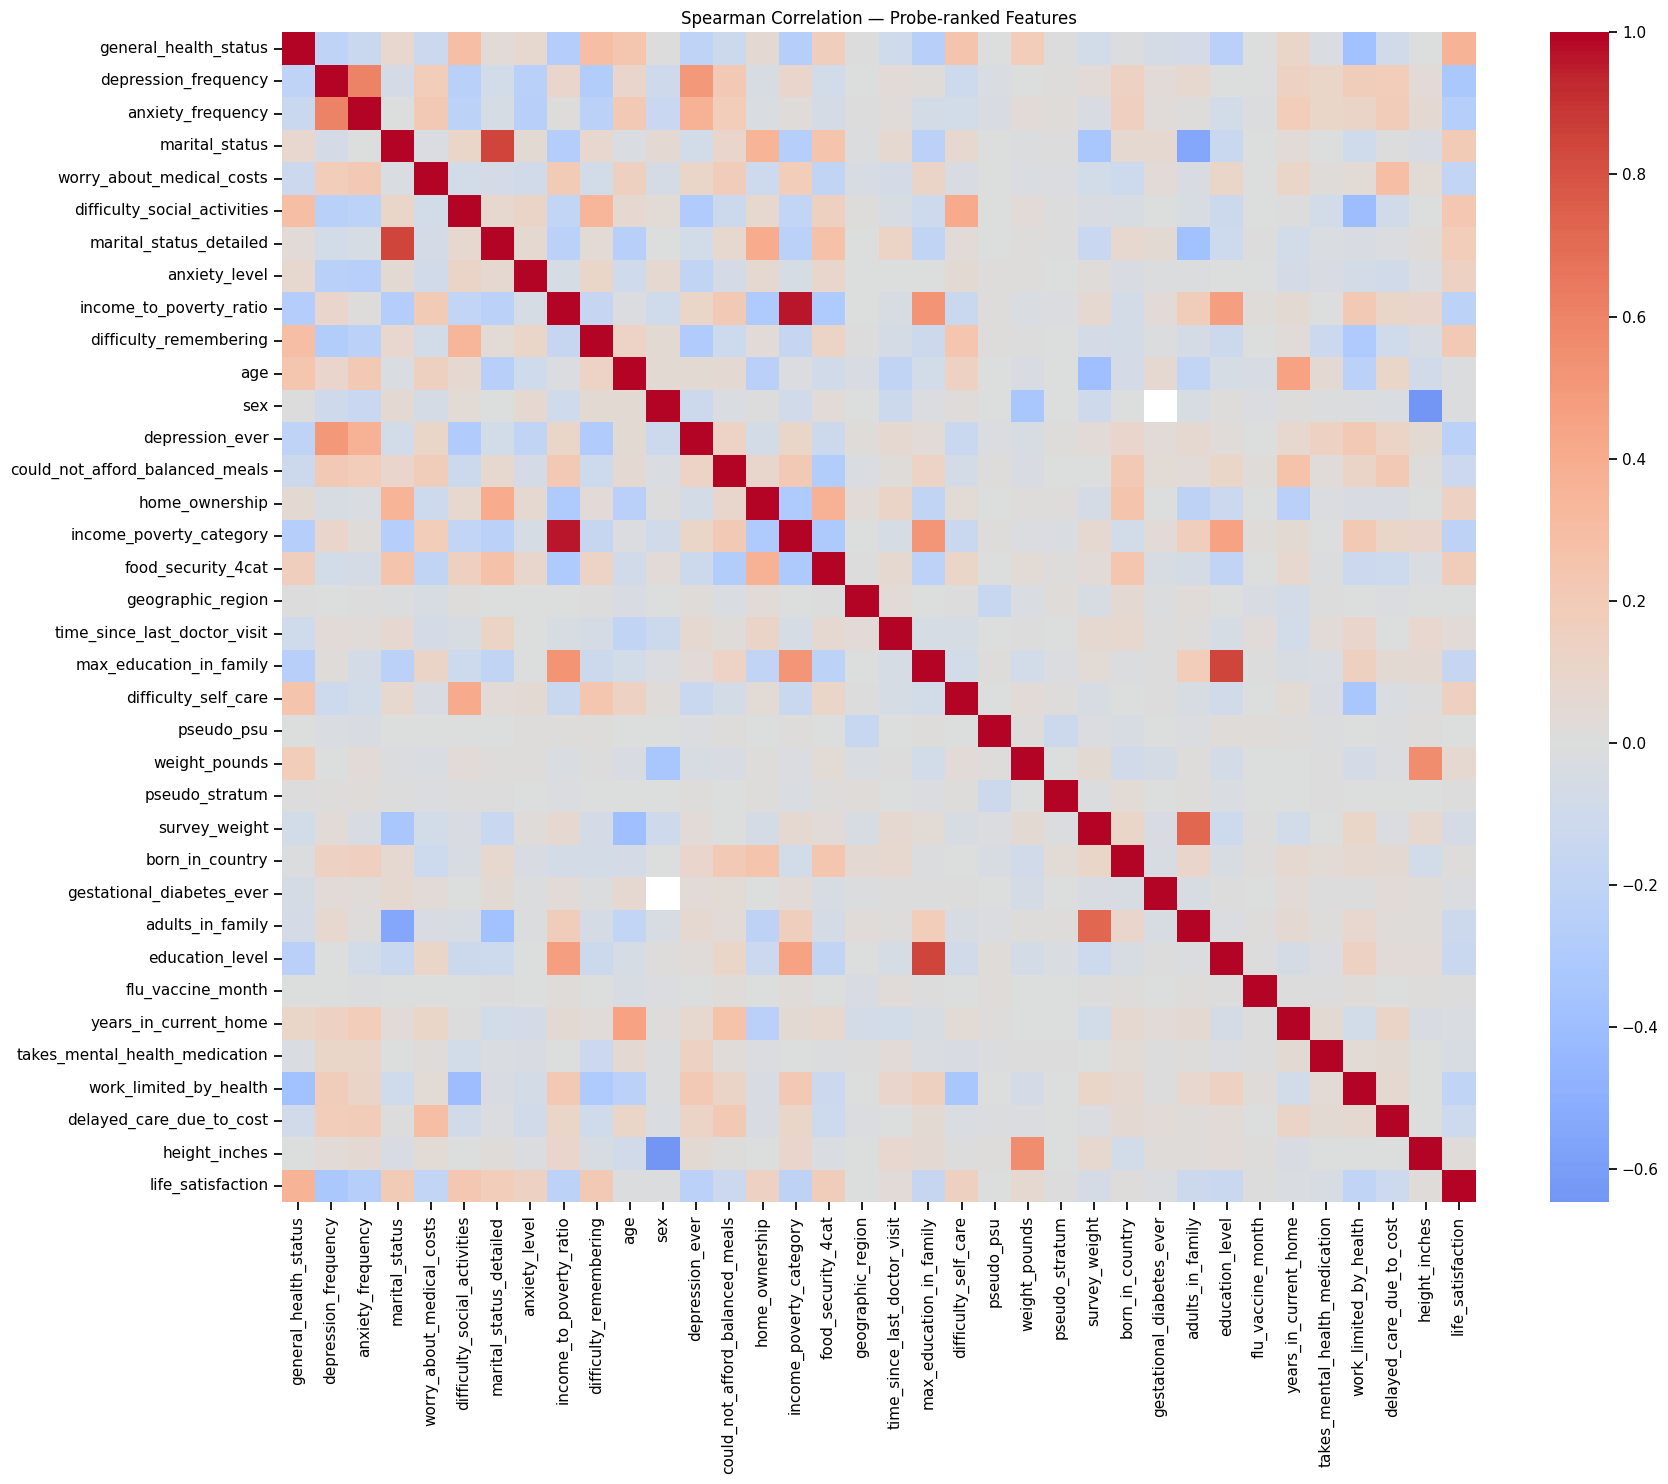

,spearman_with_target
general_health_status,0.361369
depression_frequency,-0.322500
anxiety_frequency,-0.259551
difficulty_social_activities,0.229138
depression_ever,-0.227277
income_to_poverty_ratio,-0.218635
difficulty_remembering,0.216128
income_poverty_category,-0.213499
work_limited_by_health,-0.198312
marital_status,0.196893


,feature_a,feature_b,spearman,abs_spearman
14403,data_year,survey_year,1.000000,1.000000
8658,children_in_family,children_in_household,0.997946,0.997946
14658,ever_used_ecigarette,ecigarette_status,0.996592,0.996592
8017,health_insurance_type,private_health_insurance,0.982371,0.982371
12146,cancer_ever,cancer_types_count,-0.980677,0.980677
14181,smoking_status,ever_smoked,0.978328,0.978328
13716,interview_quarter,interview_month,0.971614,0.971614
696,income_to_poverty_ratio,income_poverty_category,0.961113,0.961113
10949,adults_in_family,adults_in_household,0.959253,0.959253
11048,has_senior_gov_insurance,senior_government_insurance,0.948933,0.948933


In [16]:
ranked_raw = [f for f in importance["feature"] if f in train.columns]
heatmap_features = [f for f in ranked_raw if pd.api.types.is_numeric_dtype(train[f])][:35]

corr = train[heatmap_features + [CFG.TARGET]].corr(method="spearman")
plt.figure(figsize=(18, 15))
sns.heatmap(corr, cmap="coolwarm", center=0, square=False)
plt.title("Spearman Correlation — Probe-ranked Features")
plt.tight_layout()
plt.show()

target_corr = corr[CFG.TARGET].drop(CFG.TARGET).sort_values(key=np.abs, ascending=False)
display(target_corr.rename("spearman_with_target").to_frame().head(30))

# Also surface highly redundant feature pairs for repair/selection insight.
raw_numeric = [c for c in test.columns if pd.api.types.is_numeric_dtype(train[c])]
raw_corr = train[raw_numeric].corr(method="spearman")
mask = np.triu(np.ones(raw_corr.shape, dtype=bool), k=1)
pairs = (
    raw_corr.where(mask)
    .stack()
    .rename("spearman")
    .reset_index()
    .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
)
pairs["abs_spearman"] = pairs["spearman"].abs()
display(pairs.sort_values("abs_spearman", ascending=False).head(30))


### 4.7 Interaction exploration

These heatmaps test domain relationships identified in the audit: physical health × mental health, depression × anxiety, and poverty × food security. Cell labels show mean target; a second table reports the rate of clearly dissatisfied respondents (`life_satisfaction >= 3`).


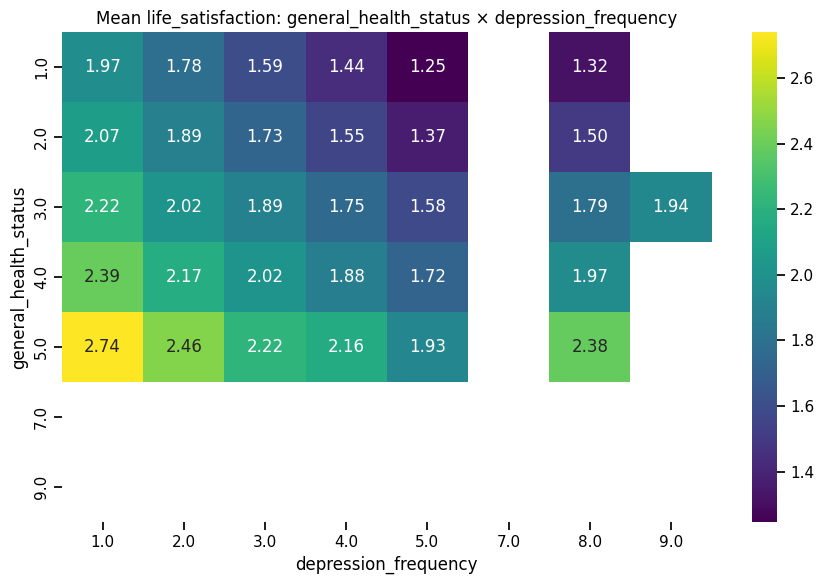

depression_frequency,1.000000,2.000000,3.000000,4.000000,5.000000,7.000000,8.000000,9.000000
general_health_status,,,,,,,,
1.000000,18.5%,7.3%,2.7%,1.2%,0.7%,nan%,1.5%,nan%
2.000000,18.7%,9.4%,3.2%,1.4%,0.9%,nan%,1.7%,nan%
3.000000,26.1%,12.7%,5.2%,2.7%,1.2%,nan%,4.5%,7.1%
4.000000,37.8%,23.3%,14.0%,6.7%,4.1%,nan%,10.7%,nan%
5.000000,57.0%,43.5%,28.1%,25.2%,14.1%,nan%,41.5%,nan%
7.000000,nan%,nan%,nan%,nan%,nan%,nan%,nan%,nan%
9.000000,nan%,nan%,nan%,nan%,nan%,nan%,nan%,nan%


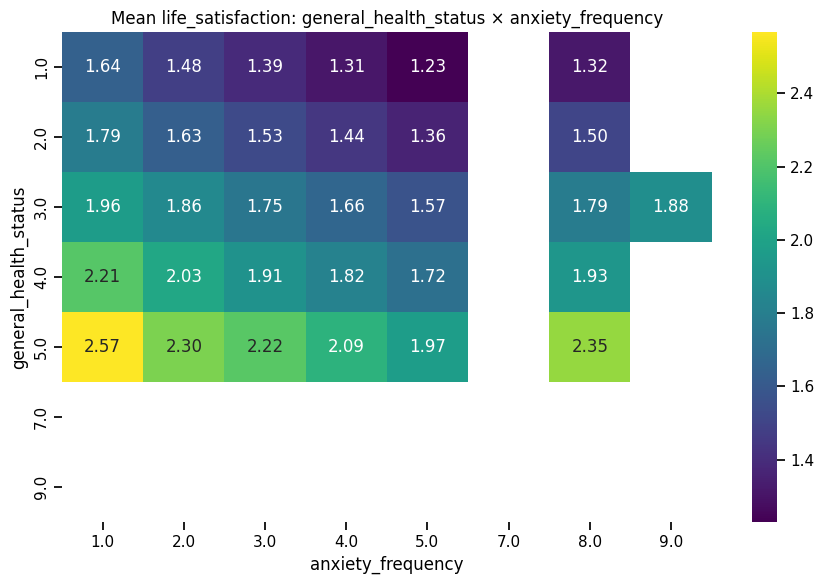

anxiety_frequency,1.000000,2.000000,3.000000,4.000000,5.000000,7.000000,8.000000,9.000000
general_health_status,,,,,,,,
1.000000,6.1%,1.4%,0.8%,1.0%,0.7%,nan%,1.7%,nan%
2.000000,7.6%,2.4%,1.5%,1.2%,1.1%,nan%,2.0%,nan%
3.000000,12.5%,5.7%,2.8%,1.7%,1.4%,nan%,4.4%,7.8%
4.000000,26.9%,15.7%,8.0%,5.1%,4.9%,nan%,9.1%,nan%
5.000000,47.9%,34.2%,27.6%,20.9%,17.0%,nan%,38.7%,nan%
7.000000,nan%,nan%,nan%,nan%,nan%,nan%,nan%,nan%
9.000000,nan%,nan%,nan%,nan%,nan%,nan%,nan%,nan%


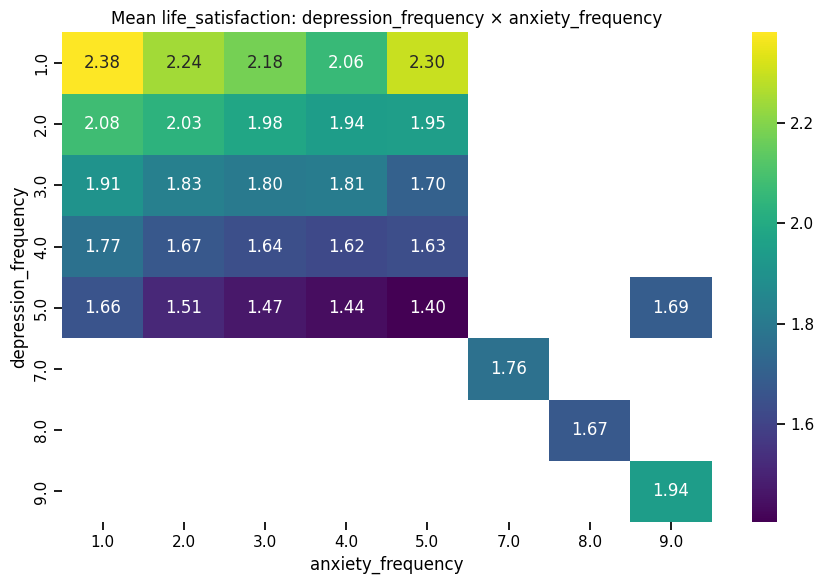

anxiety_frequency,1.000000,2.000000,3.000000,4.000000,5.000000,7.000000,8.000000,9.000000
depression_frequency,,,,,,,,
1.000000,36.5%,28.1%,23.0%,19.9%,32.7%,nan%,nan%,nan%
2.000000,19.1%,15.0%,14.1%,12.1%,13.3%,nan%,nan%,nan%
3.000000,8.9%,5.9%,5.1%,7.9%,6.1%,nan%,nan%,nan%
4.000000,6.6%,2.8%,2.3%,2.4%,4.0%,nan%,nan%,nan%
5.000000,6.4%,1.9%,1.3%,1.0%,1.3%,nan%,nan%,5.6%
7.000000,nan%,nan%,nan%,nan%,nan%,4.4%,nan%,nan%
8.000000,nan%,nan%,nan%,nan%,nan%,nan%,6.1%,nan%
9.000000,nan%,nan%,nan%,nan%,nan%,nan%,nan%,14.8%


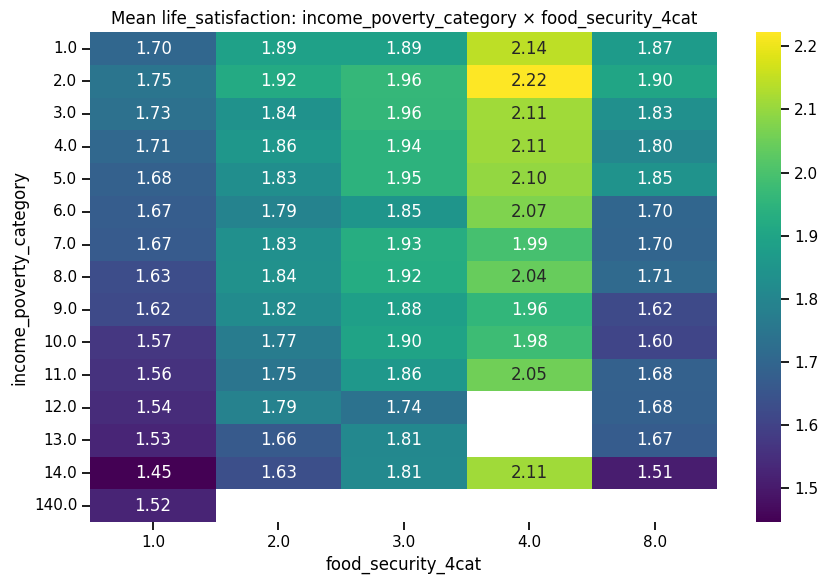

food_security_4cat,1.000000,2.000000,3.000000,4.000000,8.000000
income_poverty_category,,,,,
1.000000,6.6%,11.4%,7.7%,24.0%,11.8%
2.000000,7.4%,12.0%,17.0%,27.5%,11.2%
3.000000,7.0%,11.1%,15.0%,21.7%,9.4%
4.000000,6.6%,7.8%,14.2%,21.9%,9.1%
5.000000,5.3%,8.7%,12.9%,19.5%,9.1%
6.000000,4.8%,7.9%,8.8%,21.2%,5.3%
7.000000,4.6%,9.9%,12.1%,16.1%,6.4%
8.000000,3.9%,9.5%,10.2%,19.1%,6.4%
9.000000,3.6%,9.5%,9.8%,13.8%,3.2%


In [17]:
def interaction_heatmap(df, row_feature, col_feature, min_count=50):
    if row_feature not in df.columns or col_feature not in df.columns:
        return
    tmp = df[[row_feature, col_feature, CFG.TARGET]].dropna()
    counts = tmp.pivot_table(index=row_feature, columns=col_feature, values=CFG.TARGET, aggfunc="size", fill_value=0)
    means = tmp.pivot_table(index=row_feature, columns=col_feature, values=CFG.TARGET, aggfunc="mean")
    means = means.where(counts >= min_count)

    plt.figure(figsize=(9, 6))
    sns.heatmap(means, annot=True, fmt=".2f", cmap="viridis")
    plt.title(f"Mean {CFG.TARGET}: {row_feature} × {col_feature}")
    plt.tight_layout()
    plt.show()

    tmp = tmp.assign(dissatisfied=(tmp[CFG.TARGET] >= 3).astype(int))
    rates = tmp.pivot_table(index=row_feature, columns=col_feature, values="dissatisfied", aggfunc="mean")
    rates = rates.where(counts >= min_count)
    display(rates.style.format("{:.1%}"))

interaction_pairs = [
    ("general_health_status", "depression_frequency"),
    ("general_health_status", "anxiety_frequency"),
    ("depression_frequency", "anxiety_frequency"),
    ("income_poverty_category", "food_security_4cat"),
]

for a, b in interaction_pairs:
    interaction_heatmap(train, a, b)


## 5. Feature Engineering

The implementation follows the requested tabular feature-engineering checklist explicitly.

### 5.1 Discretization
Only `age_band` is added as a conservative discretization. Raw `age` remains available, so the tree models do not lose continuous ordering information. No mass binning is used.

### 5.2 Feature Selection
The explainability probe ranks raw/preprocessing features. V1 keeps the strongest 120 candidates, then force-keeps curated engineered features, sentinel indicators, and key domain anchors.

### 5.3 Feature Creation
Create a small set of semantic burden/count features: functional difficulty, chronic conditions, cost barriers, food insecurity, income sources, insurance, household size, mental-frequency burden, missingness, repair count, and fold-safe frequencies.

### 5.4 Clipping / Outlier Handling
No global winsorization or IQR row dropping. Repeated extreme values identified as likely survey sentinel codes are kept raw **plus explicit indicators**. This preserves information instead of turning survey codes into ordinary numeric outliers.

### 5.5 Feature Encoding
XGBoost and LightGBM receive numeric survey codes directly so ordinal ordering remains usable. CatBoost additionally treats a curated set of truly nominal codes as categorical strings. Frequency encoding for household/pseudo sampling identifiers is learned inside each fold.

No global scaling, polynomial expansion, SMOTE, generic label encoding, or global median/zero imputation is used.


In [18]:
FUNCTIONAL_DIFFICULTY_COLS = [
    "difficulty_walking_steps", "difficulty_walking_short", "difficulty_walking_medium",
    "difficulty_climbing_steps", "difficulty_using_hands", "difficulty_raising_arm",
    "difficulty_self_care", "difficulty_communicating", "difficulty_remembering",
    "difficulty_errands_alone", "difficulty_social_activities",
]

CHRONIC_CONDITION_COLS = [
    "hypertension_ever", "high_cholesterol_ever", "heart_disease_ever", "heart_attack_ever",
    "angina_ever", "stroke_ever", "asthma_ever", "diabetes_ever", "prediabetes_ever",
    "cancer_ever", "lung_disease_ever", "arthritis_ever", "dementia_ever", "chronic_fatigue_ever",
]

COST_BARRIER_YES_COLS = [
    "trouble_paying_medical_bills", "delayed_care_due_to_cost", "skipped_care_due_to_cost",
    "skipped_medication_to_save_money", "took_less_medication_to_save_money",
    "delayed_prescription_to_save_money", "skipped_prescription_due_to_cost",
    "delayed_therapy_due_to_cost", "skipped_therapy_due_to_cost",
]

INCOME_SOURCE_COLS = [
    "has_wage_income", "has_investment_income", "has_social_security_income",
    "has_disability_income", "has_public_assistance_income", "has_retirement_income", "has_other_income",
]

INSURANCE_YES_COLS = [
    "has_health_insurance", "has_private_insurance", "has_senior_gov_insurance",
    "has_lowincome_gov_insurance", "has_child_gov_insurance", "has_military_insurance",
    "has_state_health_plan", "has_other_gov_insurance",
]

FREQUENCY_COLS = [CFG.HOUSEHOLD_COL, "pseudo_stratum", "pseudo_psu"]

NOMINAL_CATBOOST_COLS = [
    "record_type", "geographic_region", "pseudo_stratum", "pseudo_psu", "sex",
    "citizenship_status", "born_in_country", "sexual_orientation", "parental_status",
    "relationship_to_child", "marital_status", "legal_marital_status", "marital_status_detailed",
    "health_insurance_type", "insurance_source_plan1", "type_of_care_provider", "home_ownership",
    "smoking_status", "ecigarette_status",
]


def count_yes(df, cols):
    valid_cols = [c for c in cols if c in df.columns]
    if not valid_cols:
        return pd.Series(0, index=df.index, dtype=np.int16)
    return (df[valid_cols] == 1).sum(axis=1).astype(np.int16)


def reverse_ordinal(series, max_valid):
    # Converts 1=worst/most frequent ... max_valid=best/never into larger=worse.
    s = pd.to_numeric(series, errors="coerce")
    out = pd.Series(np.nan, index=s.index, dtype=float)
    valid = s.between(1, max_valid)
    out.loc[valid] = (max_valid + 1) - s.loc[valid]
    return out


class SemanticFeatureEngineer:
    def __init__(self):
        self.frequency_maps_ = {}
        self.engineered_feature_names_ = []

    def fit(self, df):
        for col in FREQUENCY_COLS:
            if col in df.columns:
                self.frequency_maps_[col] = df[col].value_counts(dropna=False).to_dict()
        return self

    def transform(self, df):
        out = df.copy()
        before_cols = set(out.columns)

        # Frequency encodings are learned from the fold training set only.
        for col, mapping in self.frequency_maps_.items():
            if col in out.columns:
                out[f"{col}__frequency"] = out[col].map(mapping).fillna(0).astype(np.float32)
                out[f"{col}__log_frequency"] = np.log1p(out[f"{col}__frequency"]).astype(np.float32)

        out["functional_difficulty_count"] = count_yes(out, FUNCTIONAL_DIFFICULTY_COLS)
        out["chronic_condition_count"] = count_yes(out, CHRONIC_CONDITION_COLS)
        out["cost_barrier_count"] = count_yes(out, COST_BARRIER_YES_COLS)
        out["income_source_count"] = count_yes(out, INCOME_SOURCE_COLS)
        out["insurance_count"] = count_yes(out, INSURANCE_YES_COLS)

        # Food insecurity: 1=often, 2=sometimes, 3=never -> severity 3,2,1.
        food_severity_parts = []
        for col in ["worried_food_would_run_out", "food_did_not_last", "could_not_afford_balanced_meals"]:
            if col in out.columns:
                food_severity_parts.append(reverse_ordinal(out[col], 3).fillna(0))
        if food_severity_parts:
            out["food_insecurity_count"] = sum(food_severity_parts).astype(np.float32)
            if "received_food_assistance" in out.columns:
                out["food_insecurity_count"] += (out["received_food_assistance"] == 1).astype(np.float32)
        else:
            out["food_insecurity_count"] = 0.0

        # Mental burden: 1=daily ... 5=never -> 5 ... 1.
        mental_parts = []
        for col in ["depression_frequency", "anxiety_frequency"]:
            if col in out.columns:
                mental_parts.append(reverse_ordinal(out[col], 5).fillna(0))
        out["mental_frequency_burden"] = sum(mental_parts).astype(np.float32) if mental_parts else 0.0

        # Household size proxy. Raw counts are capped categories in the source; trees can still use their sum as a burden/context shortcut.
        hh_parts = []
        for col in ["children_in_household", "adults_in_household"]:
            if col in out.columns:
                hh_parts.append(pd.to_numeric(out[col], errors="coerce").fillna(0))
        out["household_size_proxy"] = sum(hh_parts).astype(np.float32) if hh_parts else 0.0

        # Conservative discretization only. Out-of-range sentinel ages become NaN here while raw age + sentinel flag stay present.
        if "age" in out.columns:
            valid_age = pd.to_numeric(out["age"], errors="coerce").where(pd.to_numeric(out["age"], errors="coerce").between(18, 85))
            out["age_band"] = pd.cut(
                valid_age,
                bins=[17, 24, 34, 44, 54, 64, 74, 85],
                labels=False,
                include_lowest=True,
            ).astype(float)

        # IDs: id is never a feature. household_id contributes only via fold-safe frequency encoding.
        out = out.drop(columns=[c for c in [CFG.ID_COL, CFG.HOUSEHOLD_COL] if c in out.columns])

        self.engineered_feature_names_ = [c for c in out.columns if c not in before_cols]
        return out

    def fit_transform(self, df):
        return self.fit(df).transform(df)


### 5.6 Final feature-selection guardrail

The explainability probe suggested that noisy tail features can hurt. V1 therefore keeps the top probe-ranked raw/preprocessing features, then **force-keeps all curated engineered features and key domain anchors**. This avoids an arbitrary “all columns must be used” assumption while retaining known high-value variables.


In [19]:
DOMAIN_FORCE_KEEP = [
    "general_health_status", "depression_frequency", "anxiety_frequency", "anxiety_level",
    "income_to_poverty_ratio", "income_poverty_category", "food_security_4cat", "food_security_3cat",
    "difficulty_social_activities", "difficulty_remembering", "marital_status_detailed", "marital_status",
    "age", "survey_weight", "row_missing_count_raw", "row_missing_count_after_repair",
    "repaired_value_count", "special_code_count",
]


def choose_final_features(X_train_engineered, engineered_names):
    ranked = [f for f in probe_top_features if f in X_train_engineered.columns]
    engineered = [f for f in engineered_names if f in X_train_engineered.columns]
    forced = [f for f in DOMAIN_FORCE_KEEP if f in X_train_engineered.columns]
    sentinel = [f for f in X_train_engineered.columns if f.endswith("__special_code")]
    selected = list(dict.fromkeys(ranked[:CFG.TOP_N_PROBE_FEATURES] + engineered + forced + sentinel))
    return selected

# Preview using the probe split only; final folds relearn all unsupervised mappings.
_preview_pre = FoldPreprocessor(CFG.REPAIR_MIN_ACCURACY, CFG.REPAIR_MIN_SUPPORT).fit(probe_raw_train)
_preview_tr = _preview_pre.transform(probe_raw_train)
_preview_fe = SemanticFeatureEngineer().fit(_preview_tr)
_preview_tr_fe = _preview_fe.transform(_preview_tr)
preview_features = choose_final_features(_preview_tr_fe, _preview_fe.engineered_feature_names_)

print("Final-feature preview count:", len(preview_features))
print("Engineered preview:", _preview_fe.engineered_feature_names_)
print("First 40 selected:", preview_features[:40])


Final-feature preview count: 143
Engineered preview: ['household_id__frequency', 'household_id__log_frequency', 'pseudo_stratum__frequency', 'pseudo_stratum__log_frequency', 'pseudo_psu__frequency', 'pseudo_psu__log_frequency', 'functional_difficulty_count', 'chronic_condition_count', 'cost_barrier_count', 'income_source_count', 'insurance_count', 'food_insecurity_count', 'mental_frequency_burden', 'household_size_proxy', 'age_band']
First 40 selected: ['general_health_status', 'depression_frequency', 'anxiety_frequency', 'marital_status', 'worry_about_medical_costs', 'difficulty_social_activities', 'marital_status_detailed', 'anxiety_level', 'income_to_poverty_ratio', 'difficulty_remembering', 'age', 'sex', 'depression_ever', 'could_not_afford_balanced_meals', 'home_ownership', 'income_poverty_category', 'food_security_4cat', 'geographic_region', 'time_since_last_doctor_visit', 'max_education_in_family', 'difficulty_self_care', 'pseudo_psu', 'weight_pounds', 'pseudo_stratum', 'survey_

## 6. Modeling

Three independent SOTA gradient-boosted tree regressors are trained on the same grouped folds:

1. **DMLC XGBoost**
2. **CatBoost**
3. **LightGBM**

No sample rebalancing and no `survey_weight` training weights are used. `survey_weight` remains an ordinary input feature because Kaggle QWK scores each test row, not a survey-population-weighted estimate.


In [20]:
def prepare_catboost_frame(X, selected_features):
    Xc = X[selected_features].copy()
    cat_cols = [c for c in NOMINAL_CATBOOST_COLS if c in Xc.columns]
    for c in cat_cols:
        s = Xc[c]
        Xc[c] = s.map(lambda v: "__MISSING__" if pd.isna(v) else str(v))
    return Xc, cat_cols


def make_lgb(seed, device_mode="cpu"):
    params = dict(
        objective="regression_l2",
        n_estimators=CFG.LGB_N_ESTIMATORS,
        learning_rate=CFG.LEARNING_RATE,
        num_leaves=31,
        min_child_samples=40,
        max_depth=-1,
        subsample=0.85,
        subsample_freq=1,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=4.0,
        random_state=seed,
        n_jobs=-1,
        verbosity=-1,
    )
    if device_mode in {"cuda", "gpu"}:
        params.update(device_type=device_mode, max_bin=63)
    else:
        params.update(device_type="cpu")
    return lgb.LGBMRegressor(**params)

def make_xgb(seed, use_gpu=True):
    params = dict(
        objective="reg:squarederror",
        eval_metric="rmse",
        n_estimators=CFG.XGB_N_ESTIMATORS,
        learning_rate=CFG.LEARNING_RATE,
        max_depth=6,
        min_child_weight=8,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=4.0,
        tree_method="hist",
        random_state=seed,
        n_jobs=-1,
        early_stopping_rounds=CFG.EARLY_STOPPING,
    )
    if use_gpu:
        params["device"] = "cuda"
    return xgb.XGBRegressor(**params)


def make_cat(seed, use_gpu=True):
    params = dict(
        loss_function="RMSE",
        eval_metric="RMSE",
        iterations=CFG.CAT_ITERATIONS,
        learning_rate=CFG.LEARNING_RATE,
        depth=7,
        l2_leaf_reg=6.0,
        random_strength=0.5,
        random_seed=seed,
        od_type="Iter",
        od_wait=CFG.EARLY_STOPPING,
        allow_writing_files=False,
        verbose=CFG.VERBOSE,
    )
    if use_gpu:
        params.update(task_type="GPU", devices=CFG.CAT_DEVICES)
    else:
        params.update(task_type="CPU", thread_count=-1)
    return CatBoostRegressor(**params)


def fit_predict_lgb(X_tr, y_tr, X_va, y_va, X_te, seed):
    device_modes = ["cuda", "gpu", "cpu"] if CFG.USE_GPU else ["cpu"]
    last_error = None
    for device_mode in device_modes:
        model = make_lgb(seed, device_mode=device_mode)
        try:
            model.fit(
                X_tr,
                y_tr,
                eval_set=[(X_va, y_va)],
                eval_metric="rmse",
                callbacks=[
                    lgb.early_stopping(CFG.EARLY_STOPPING, verbose=False),
                    lgb.log_evaluation(CFG.VERBOSE),
                ],
            )
            print("LightGBM device:", device_mode.upper())
            va = model.predict(X_va, num_iteration=model.best_iteration_)
            te = model.predict(X_te, num_iteration=model.best_iteration_)
            return model, va, te
        except Exception as e:
            last_error = e
            if device_mode != "cpu":
                print(f"LightGBM {device_mode.upper()} failed -> next fallback:", repr(e))
                gc.collect()
                continue
            raise last_error

def fit_predict_xgb(X_tr, y_tr, X_va, y_va, X_te, seed):
    for gpu_flag in ([True, False] if CFG.USE_GPU else [False]):
        model = make_xgb(seed, use_gpu=gpu_flag)
        try:
            model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
            print("XGBoost device:", "CUDA" if gpu_flag else "CPU")
            return model, model.predict(X_va), model.predict(X_te)
        except Exception as e:
            if gpu_flag:
                print("XGBoost CUDA failed -> CPU fallback:", repr(e))
                gc.collect()
                continue
            raise


def fit_predict_cat(X_tr, y_tr, X_va, y_va, X_te, cat_cols, seed):
    for gpu_flag in ([True, False] if CFG.USE_GPU else [False]):
        model = make_cat(seed, use_gpu=gpu_flag)
        try:
            model.fit(
                X_tr,
                y_tr,
                eval_set=(X_va, y_va),
                cat_features=cat_cols,
                use_best_model=True,
            )
            print("CatBoost device:", f"GPU {CFG.CAT_DEVICES}" if gpu_flag else "CPU")
            return model, model.predict(X_va), model.predict(X_te)
        except Exception as e:
            if gpu_flag:
                print("CatBoost GPU failed -> CPU fallback:", repr(e))
                gc.collect()
                continue
            raise


### 6.1 Five-fold grouped training

Every fold performs preprocessing and feature engineering from scratch using only that fold's training partition. This protects the OOF estimate from duplicate leakage and unsupervised mapping/frequency leakage.


In [21]:
model_names = ["lgb", "xgb", "cat"]
oof_cont = {m: np.zeros(len(train), dtype=np.float64) for m in model_names}
test_cont = {m: np.zeros(len(test), dtype=np.float64) for m in model_names}
fold_id = np.full(len(train), -1, dtype=np.int8)

fold_metric_rows = []
feature_importance_rows = []
selected_features_by_fold = {}
repair_reports_by_fold = {}

for fold, (tr_idx, va_idx) in enumerate(folds):
    print("\n" + "=" * 90)
    print(f"FOLD {fold + 1}/{CFG.N_FOLDS}")
    print("=" * 90)

    raw_tr = train.iloc[tr_idx].drop(columns=[CFG.TARGET]).copy()
    raw_va = train.iloc[va_idx].drop(columns=[CFG.TARGET]).copy()
    raw_te = test.copy()
    y_tr = y[tr_idx]
    y_va = y[va_idx]
    fold_id[va_idx] = fold

    # Fold-safe preprocessing.
    pre = FoldPreprocessor(CFG.REPAIR_MIN_ACCURACY, CFG.REPAIR_MIN_SUPPORT).fit(raw_tr)
    p_tr = pre.transform(raw_tr)
    p_va = pre.transform(raw_va)
    p_te = pre.transform(raw_te)
    repair_reports_by_fold[fold] = pre.repair_report_.copy()

    # Fold-safe semantic feature engineering / frequency encoding.
    fe = SemanticFeatureEngineer().fit(p_tr)
    X_tr_all = fe.transform(p_tr)
    X_va_all = fe.transform(p_va)
    X_te_all = fe.transform(p_te)

    selected_features = choose_final_features(X_tr_all, fe.engineered_feature_names_)
    selected_features_by_fold[fold] = selected_features

    # Align columns defensively.
    missing_va = [c for c in selected_features if c not in X_va_all.columns]
    missing_te = [c for c in selected_features if c not in X_te_all.columns]
    if missing_va or missing_te:
        raise RuntimeError(f"Feature alignment failed. valid_missing={missing_va}, test_missing={missing_te}")

    X_tr_num = X_tr_all[selected_features]
    X_va_num = X_va_all[selected_features]
    X_te_num = X_te_all[selected_features]

    print("Selected features:", len(selected_features))
    print("Repair rules accepted:", int(pre.repair_report_["accepted"].sum()) if len(pre.repair_report_) else 0)

    for model_name in model_names:
        print("\n" + "-" * 70)
        print(f"{model_name.upper()} | fold {fold + 1}")
        print("-" * 70)
        seed = CFG.SEED + 100 * fold + {"lgb": 1, "xgb": 2, "cat": 3}[model_name]

        if model_name == "lgb":
            model, va_pred, te_pred = fit_predict_lgb(X_tr_num, y_tr, X_va_num, y_va, X_te_num, seed)
        elif model_name == "xgb":
            model, va_pred, te_pred = fit_predict_xgb(X_tr_num, y_tr, X_va_num, y_va, X_te_num, seed)
        else:
            X_tr_cat, cat_cols = prepare_catboost_frame(X_tr_all, selected_features)
            X_va_cat, _ = prepare_catboost_frame(X_va_all, selected_features)
            X_te_cat, _ = prepare_catboost_frame(X_te_all, selected_features)
            model, va_pred, te_pred = fit_predict_cat(X_tr_cat, y_tr, X_va_cat, y_va, X_te_cat, cat_cols, seed)

        va_pred = np.asarray(va_pred, dtype=float)
        te_pred = np.asarray(te_pred, dtype=float)
        oof_cont[model_name][va_idx] = va_pred
        test_cont[model_name] += te_pred / CFG.N_FOLDS

        fold_rmse = mean_squared_error(y_va, va_pred) ** 0.5
        fold_t, fold_qwk_cal = optimize_thresholds(y_va, va_pred, maxiter=100)
        fold_qwk_round = qwk(y_va, np.clip(np.rint(va_pred), 1, 4).astype(int))
        fold_metric_rows.append({
            "fold": fold,
            "model": model_name,
            "rmse": fold_rmse,
            "naive_round_qwk": fold_qwk_round,
            "fold_calibrated_qwk_diagnostic": fold_qwk_cal,
            "t1": fold_t[0], "t2": fold_t[1], "t3": fold_t[2],
        })
        print(f"RMSE={fold_rmse:.6f} | naive QWK={fold_qwk_round:.6f} | diagnostic calibrated QWK={fold_qwk_cal:.6f}")

        # Feature importance. CatBoost importance is prediction-value change; LGB/XGB use model-native values.
        try:
            if model_name == "lgb":
                imp = model.booster_.feature_importance(importance_type="gain")
            elif model_name == "xgb":
                imp = model.feature_importances_
            else:
                imp = model.get_feature_importance()
            for f, v in zip(selected_features, imp):
                feature_importance_rows.append({"fold": fold, "model": model_name, "feature": f, "importance": float(v)})
        except Exception as e:
            print("Feature importance skipped:", e)

        del model
        gc.collect()

fold_metrics = pd.DataFrame(fold_metric_rows)
display(fold_metrics)



FOLD 1/5
Selected features: 143
Repair rules accepted: 11

----------------------------------------------------------------------
LGB | fold 1
----------------------------------------------------------------------


[LightGBM] [Fatal] CUDA Tree Learner was not enabled in this build.
Please recompile with CMake option -DUSE_CUDA=1


LightGBM CUDA failed -> next fallback: LightGBMError('CUDA Tree Learner was not enabled in this build.\nPlease recompile with CMake option -DUSE_CUDA=1')


1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.


[250]	valid_0's rmse: 0.514193	valid_0's l2: 0.264394
[500]	valid_0's rmse: 0.513338	valid_0's l2: 0.263516
[750]	valid_0's rmse: 0.513289	valid_0's l2: 0.263465
LightGBM device: GPU
RMSE=0.513228 | naive QWK=0.433428 | diagnostic calibrated QWK=0.491795

----------------------------------------------------------------------
XGB | fold 1
----------------------------------------------------------------------
XGBoost device: CUDA
RMSE=0.513363 | naive QWK=0.434302 | diagnostic calibrated QWK=0.491798

----------------------------------------------------------------------
CAT | fold 1
----------------------------------------------------------------------
0:	learn: 0.6041421	test: 0.6054180	best: 0.6054180 (0)	total: 174ms	remaining: 20m 17s
250:	learn: 0.5148480	test: 0.5165796	best: 0.5165796 (250)	total: 6.35s	remaining: 2m 50s
500:	learn: 0.5094119	test: 0.5149701	best: 0.5149686 (498)	total: 12.6s	remaining: 2m 43s
750:	learn: 0.5049568	test: 0.5142329	best: 0.5142327 (749)	total: 18.

...

[LightGBM] [Fatal] CUDA Tree Learner was not enabled in this build.
Please recompile with CMake option -DUSE_CUDA=1


[250]	valid_0's rmse: 0.518705	valid_0's l2: 0.269055
[500]	valid_0's rmse: 0.517725	valid_0's l2: 0.26804
[750]	valid_0's rmse: 0.51755	valid_0's l2: 0.267858
[1000]	valid_0's rmse: 0.517363	valid_0's l2: 0.267664
[1250]	valid_0's rmse: 0.517325	valid_0's l2: 0.267625
LightGBM device: GPU
RMSE=0.517225 | naive QWK=0.415495 | diagnostic calibrated QWK=0.469178

----------------------------------------------------------------------
XGB | fold 4
----------------------------------------------------------------------
XGBoost device: CUDA
RMSE=0.517806 | naive QWK=0.414023 | diagnostic calibrated QWK=0.465625

----------------------------------------------------------------------
CAT | fold 4
----------------------------------------------------------------------
0:	learn: 0.6048620	test: 0.6025135	best: 0.6025135 (0)	total: 34.8ms	remaining: 4m 3s
250:	learn: 0.5135527	test: 0.5205772	best: 0.5205772 (250)	total: 6.31s	remaining: 2m 49s
500:	learn: 0.5081405	test: 0.5189552	best: 0.5189552 

[LightGBM] [Fatal] CUDA Tree Learner was not enabled in this build.
Please recompile with CMake option -DUSE_CUDA=1


[250]	valid_0's rmse: 0.517066	valid_0's l2: 0.267357
[500]	valid_0's rmse: 0.516027	valid_0's l2: 0.266284
[750]	valid_0's rmse: 0.515779	valid_0's l2: 0.266028
[1000]	valid_0's rmse: 0.51568	valid_0's l2: 0.265926
LightGBM device: GPU
RMSE=0.515646 | naive QWK=0.430188 | diagnostic calibrated QWK=0.481554

----------------------------------------------------------------------
XGB | fold 5
----------------------------------------------------------------------
XGBoost device: CUDA
RMSE=0.515977 | naive QWK=0.431581 | diagnostic calibrated QWK=0.481792

----------------------------------------------------------------------
CAT | fold 5
----------------------------------------------------------------------
0:	learn: 0.6041172	test: 0.6049925	best: 0.6049925 (0)	total: 52.9ms	remaining: 6m 10s
250:	learn: 0.5141629	test: 0.5192725	best: 0.5192725 (250)	total: 6.12s	remaining: 2m 44s
500:	learn: 0.5090463	test: 0.5176297	best: 0.5176297 (500)	total: 12.5s	remaining: 2m 41s
750:	learn: 0.50

,fold,model,rmse,naive_round_qwk,fold_calibrated_qwk_diagnostic,t1,t2,t3
0,0,lgb,0.513228,0.433428,0.491795,1.528936,2.038646,2.530575
1,0,xgb,0.513363,0.434302,0.491798,1.528686,2.014951,2.576592
2,0,cat,0.513386,0.433145,0.493533,1.532376,2.061125,2.460051
3,1,lgb,0.515362,0.422433,0.479237,1.571267,2.035799,2.556124
4,1,xgb,0.515062,0.426613,0.479818,1.523376,2.068128,2.516433
5,1,cat,0.515315,0.423720,0.478947,1.560740,2.046632,2.436371
6,2,lgb,0.519716,0.418052,0.480847,1.559818,2.048153,2.485527
7,2,xgb,0.520466,0.415935,0.477281,1.544468,2.049052,2.516687
8,2,cat,0.520027,0.420126,0.482441,1.567610,2.056833,2.458700
9,3,lgb,0.517225,0.415495,0.469178,1.568855,2.019067,2.589956


## 7. Evaluation, Calibration & Ensemble

We report two calibration views:

- **Global OOF calibrated QWK:** useful for Kaggle post-processing selection but mildly optimistic because the same OOF labels choose the three thresholds.
- **Cross-fitted threshold QWK:** for each held-out fold, thresholds are learned from the other four OOF folds. This is the more trustworthy estimate.

Naive rounding is also shown to quantify the value of respecting the ordinal metric.


In [22]:
def crossfit_threshold_score(y_true, continuous_pred, fold_ids):
    y_true = np.asarray(y_true)
    continuous_pred = np.asarray(continuous_pred)
    fold_ids = np.asarray(fold_ids)
    calibrated = np.zeros(len(y_true), dtype=int)
    thresholds = {}

    for f in sorted(np.unique(fold_ids)):
        train_mask = fold_ids != f
        valid_mask = fold_ids == f
        t, _ = optimize_thresholds(y_true[train_mask], continuous_pred[train_mask], maxiter=140)
        calibrated[valid_mask] = apply_thresholds(continuous_pred[valid_mask], t)
        thresholds[int(f)] = t
    return qwk(y_true, calibrated), calibrated, thresholds

model_eval_rows = []
model_thresholds = {}
model_crossfit_labels = {}

for m in model_names:
    pred = oof_cont[m]
    naive = np.clip(np.rint(pred), 1, 4).astype(int)
    global_t, global_score = optimize_thresholds(y, pred)
    cross_score, cross_labels, cross_t = crossfit_threshold_score(y, pred, fold_id)
    model_thresholds[m] = global_t
    model_crossfit_labels[m] = cross_labels

    model_eval_rows.append({
        "model": m,
        "oof_rmse": mean_squared_error(y, pred) ** 0.5,
        "naive_round_qwk": qwk(y, naive),
        "global_calibrated_qwk": global_score,
        "crossfit_threshold_qwk": cross_score,
        "t1": global_t[0], "t2": global_t[1], "t3": global_t[2],
    })

model_eval = pd.DataFrame(model_eval_rows).sort_values("crossfit_threshold_qwk", ascending=False)
display(model_eval)


,model,oof_rmse,naive_round_qwk,global_calibrated_qwk,crossfit_threshold_qwk,t1,t2,t3
2,cat,0.516152,0.423915,0.479600,0.478022,1.549639,2.032923,2.521910
0,lgb,0.516240,0.423927,0.478691,0.477512,1.559351,2.041989,2.544589
1,xgb,0.516541,0.424501,0.477611,0.477327,1.563509,2.035802,2.530716


### 7.1 Equal blend first, then conservative weight search

Model predictions are already on the same latent target scale, so V1 blends them directly. Weight search is intentionally low-dimensional. It only replaces equal weights if the OOF gain exceeds a guardrail (`0.0015` QWK); otherwise the simpler equal blend wins.


In [23]:
pred_matrix_oof = np.column_stack([oof_cont[m] for m in model_names])
pred_matrix_test = np.column_stack([test_cont[m] for m in model_names])

equal_weights = np.ones(len(model_names), dtype=float) / len(model_names)
equal_oof = pred_matrix_oof @ equal_weights
equal_test = pred_matrix_test @ equal_weights
equal_t, equal_global_qwk = optimize_thresholds(y, equal_oof)
equal_cross_qwk, equal_cross_labels, equal_cross_t = crossfit_threshold_score(y, equal_oof, fold_id)

print("Equal weights:", dict(zip(model_names, equal_weights)))
print("Equal blend global thresholds:", np.round(equal_t, 6))
print("Equal blend global calibrated QWK:", round(equal_global_qwk, 6))
print("Equal blend cross-fitted threshold QWK:", round(equal_cross_qwk, 6))

# Cheap stage: random simplex search with equal-blend thresholds fixed.
rng = np.random.default_rng(CFG.SEED + 999)
weight_candidates = [equal_weights]
weight_candidates.extend(rng.dirichlet(np.ones(len(model_names)), size=CFG.BLEND_RANDOM_CANDIDATES))

quick_rows = []
for w in weight_candidates:
    p = pred_matrix_oof @ np.asarray(w)
    score = qwk(y, apply_thresholds(p, equal_t))
    quick_rows.append((score, np.asarray(w)))
quick_rows.sort(key=lambda x: x[0], reverse=True)

# Refine only the strongest candidates by recalibrating thresholds.
refined = []
seen = set()
for _, w in quick_rows[:CFG.BLEND_TOP_K_REFINE]:
    key = tuple(np.round(w, 6))
    if key in seen:
        continue
    seen.add(key)
    p = pred_matrix_oof @ w
    t, score = optimize_thresholds(y, p, starts=[equal_t, initial_thresholds_from_distribution(y, p)], maxiter=140)
    refined.append({"weights": w, "thresholds": t, "score": score})

best_refined = max(refined, key=lambda d: d["score"]) if refined else {"weights": equal_weights, "thresholds": equal_t, "score": equal_global_qwk}
blend_gain = best_refined["score"] - equal_global_qwk

if blend_gain >= CFG.MIN_BLEND_GAIN:
    final_weights = best_refined["weights"]
    final_thresholds = best_refined["thresholds"]
    blend_choice = "optimized"
else:
    final_weights = equal_weights
    final_thresholds = equal_t
    blend_choice = "equal"

final_oof_cont = pred_matrix_oof @ final_weights
final_test_cont = pred_matrix_test @ final_weights
final_oof_class = apply_thresholds(final_oof_cont, final_thresholds)
final_test_class = apply_thresholds(final_test_cont, final_thresholds)
final_cross_qwk, final_crossfit_labels, final_cross_t = crossfit_threshold_score(y, final_oof_cont, fold_id)

print("\nBlend search best global gain vs equal:", round(blend_gain, 6))
print("Chosen blend:", blend_choice)
print("Chosen weights:", dict(zip(model_names, np.round(final_weights, 6))))
print("Final thresholds:", np.round(final_thresholds, 6))
print("Final global OOF QWK:", round(qwk(y, final_oof_class), 6))
print("Final cross-fitted threshold QWK:", round(final_cross_qwk, 6))
print("Final test class distribution:")
print(pd.Series(final_test_class).value_counts(normalize=True).sort_index())


Equal weights: {'lgb': np.float64(0.3333333333333333), 'xgb': np.float64(0.3333333333333333), 'cat': np.float64(0.3333333333333333)}
Equal blend global thresholds: [1.56384  2.032787 2.516481]
Equal blend global calibrated QWK: 0.480481
Equal blend cross-fitted threshold QWK: 0.479662

Blend search best global gain vs equal: 0.000723
Chosen blend: equal
Chosen weights: {'lgb': np.float64(0.333333), 'xgb': np.float64(0.333333), 'cat': np.float64(0.333333)}
Final thresholds: [1.56384  2.032787 2.516481]
Final global OOF QWK: 0.480481
Final cross-fitted threshold QWK: 0.479662
Final test class distribution:
1    0.487532
2    0.417873
3    0.080997
4    0.013597
Name: proportion, dtype: float64


### 7.2 Final feature importance


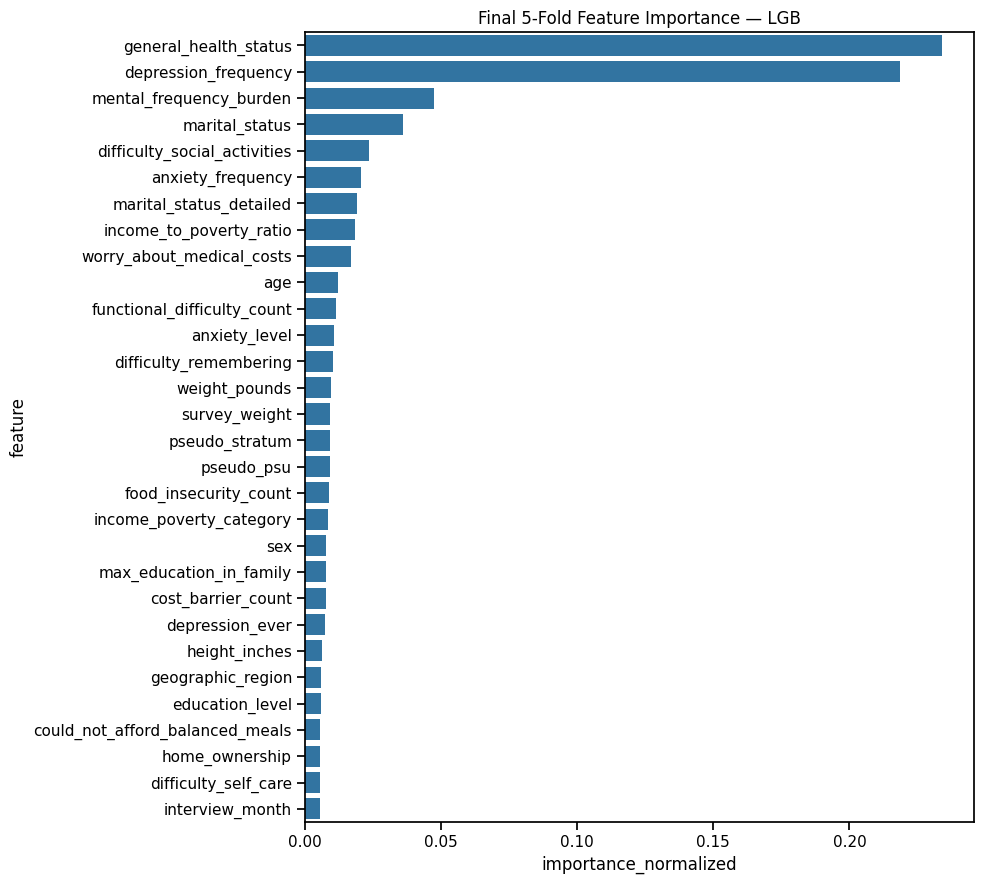

,model,feature,importance,importance_normalized
203,lgb,general_health_status,46340.063205,0.234087
171,lgb,depression_frequency,43294.125656,0.218700
243,lgb,mental_frequency_burden,9334.955885,0.047156
240,lgb,marital_status,7124.707472,0.035990
181,lgb,difficulty_social_activities,4642.581553,0.023452
148,lgb,anxiety_frequency,4043.873210,0.020428
241,lgb,marital_status_detailed,3762.190680,0.019005
230,lgb,income_to_poverty_ratio,3630.397455,0.018339
284,lgb,worry_about_medical_costs,3336.947069,0.016857
145,lgb,age,2347.497672,0.011858


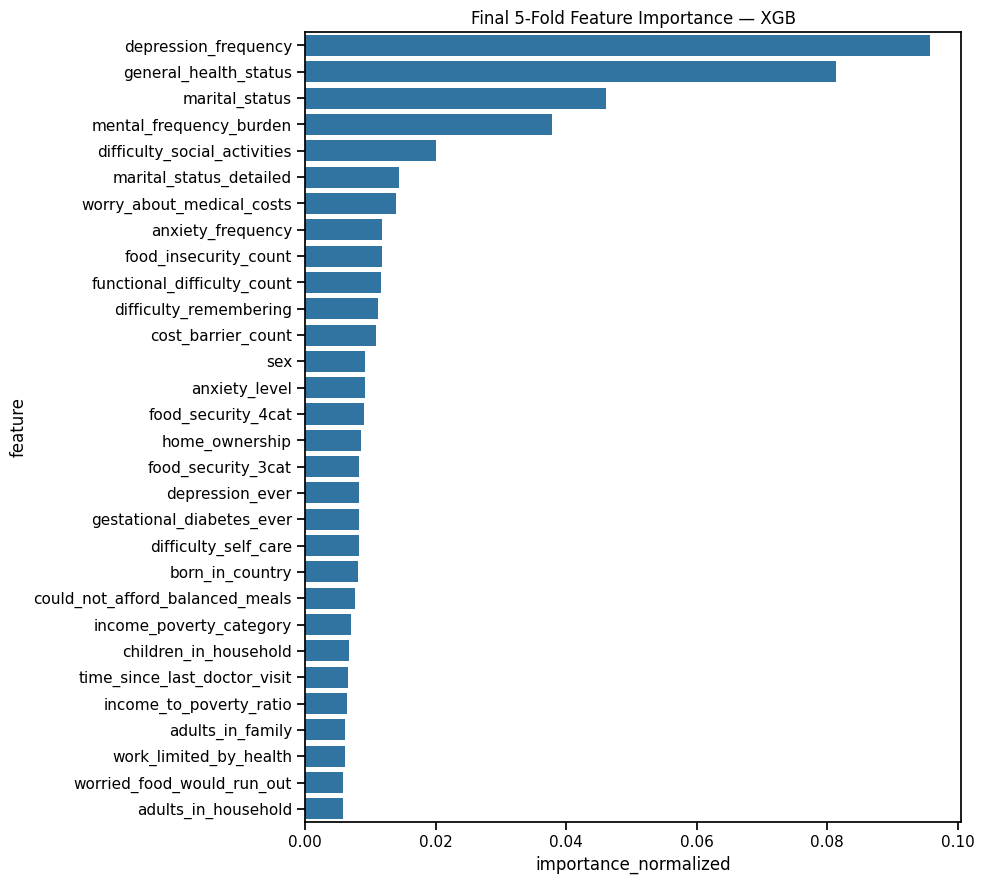

,model,feature,importance,importance_normalized
314,xgb,depression_frequency,0.095701,0.095701
346,xgb,general_health_status,0.081295,0.081295
383,xgb,marital_status,0.046115,0.046115
386,xgb,mental_frequency_burden,0.037790,0.037790
324,xgb,difficulty_social_activities,0.020086,0.020086
384,xgb,marital_status_detailed,0.014344,0.014344
427,xgb,worry_about_medical_costs,0.013964,0.013964
291,xgb,anxiety_frequency,0.011830,0.011830
342,xgb,food_insecurity_count,0.011800,0.011800
345,xgb,functional_difficulty_count,0.011644,0.011644


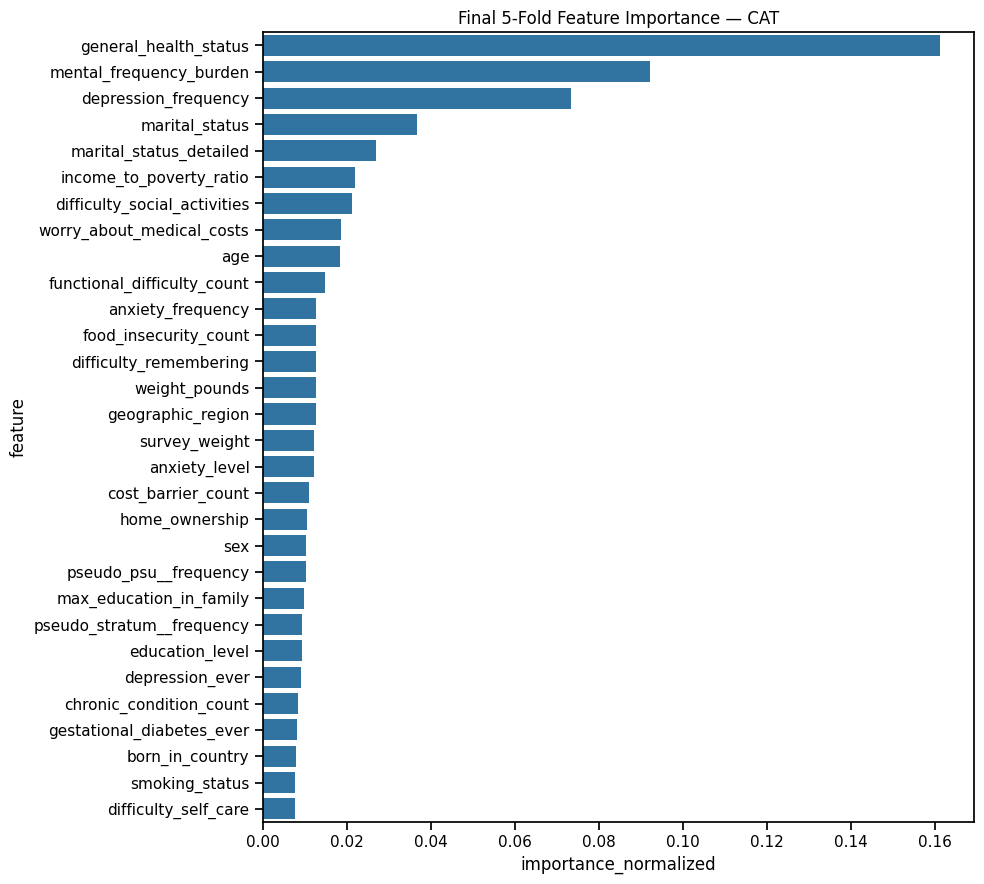

,model,feature,importance,importance_normalized
60,cat,general_health_status,16.124721,0.161247
100,cat,mental_frequency_burden,9.228044,0.092280
28,cat,depression_frequency,7.333593,0.073336
97,cat,marital_status,3.683480,0.036835
98,cat,marital_status_detailed,2.694613,0.026946
87,cat,income_to_poverty_ratio,2.204128,0.022041
38,cat,difficulty_social_activities,2.124357,0.021244
141,cat,worry_about_medical_costs,1.860649,0.018606
2,cat,age,1.836943,0.018369
59,cat,functional_difficulty_count,1.481549,0.014815


In [24]:
feature_importance_df = pd.DataFrame(feature_importance_rows)
if len(feature_importance_df):
    mean_fi = (
        feature_importance_df.groupby(["model", "feature"], as_index=False)["importance"].mean()
    )
    mean_fi["importance_normalized"] = mean_fi.groupby("model")["importance"].transform(
        lambda s: s / max(s.sum(), 1e-12)
    )

    for m in model_names:
        temp = mean_fi[mean_fi["model"] == m].sort_values("importance_normalized", ascending=False).head(30)
        plt.figure(figsize=(10, 9))
        sns.barplot(data=temp, x="importance_normalized", y="feature")
        plt.title(f"Final 5-Fold Feature Importance — {m.upper()}")
        plt.tight_layout()
        plt.show()
        display(temp.head(20))
else:
    mean_fi = pd.DataFrame()
    print("No feature importance collected.")


### 7.3 Error analysis

QWK penalizes long-distance mistakes quadratically. The confusion matrix and large-error slices help distinguish “class imbalance” from actual ordinal failures.


In [25]:
conf = pd.crosstab(
    pd.Series(y, name="actual"),
    pd.Series(final_crossfit_labels, name="crossfit_prediction"),
    normalize="index",
)
display(conf.style.format("{:.1%}"))

error_df = train[[CFG.TARGET]].copy()
error_df["oof_continuous"] = final_oof_cont
error_df["oof_crossfit_class"] = final_crossfit_labels
error_df["absolute_class_error"] = np.abs(error_df[CFG.TARGET] - error_df["oof_crossfit_class"])

display(error_df.groupby(CFG.TARGET)["absolute_class_error"].agg(["mean", "median", "max", "count"]))
print("Rate of 2+ class errors:", (error_df["absolute_class_error"] >= 2).mean())


crossfit_prediction,1,2,3,4
actual,,,,
1,72.3%,26.1%,1.5%,0.1%
2,32.9%,55.8%,10.3%,1.0%
3,4.9%,37.6%,43.5%,14.0%
4,15.9%,23.1%,33.3%,27.8%


,mean,median,max,count
life_satisfaction,,,,
1,0.294847,0.0,3,42968
2,0.451742,0.0,2,48189
3,0.613936,1.0,2,3559
4,1.270997,1.0,3,893


Rate of 2+ class errors: 0.01759248606302754


## 8. Submission & Artifacts

Critical rule: **preserve `sample_submission.id` exactly**. Predictions correspond to the row order of `test_final.csv`, while the submission identifier column comes from the provided sample file.


In [26]:
submission = sample_submission.copy()
assert len(submission) == len(final_test_class)
assert CFG.TARGET in submission.columns, f"Expected {CFG.TARGET} in sample_submission columns: {submission.columns.tolist()}"

# Never overwrite the sample ID with test_final.id.
original_submission_ids = submission[CFG.ID_COL].copy() if CFG.ID_COL in submission.columns else None
submission[CFG.TARGET] = final_test_class.astype(int)
if original_submission_ids is not None:
    assert np.array_equal(submission[CFG.ID_COL].values, original_submission_ids.values)

assert submission[CFG.TARGET].isin([1, 2, 3, 4]).all()
assert submission.shape == sample_submission.shape
assert submission.columns.tolist() == sample_submission.columns.tolist()

display(submission.head(10))
print(submission[CFG.TARGET].value_counts(normalize=True).sort_index())

submission_path = CFG.OUTPUT_DIR / "submission_v1.csv"
submission.to_csv(submission_path, index=False)
print("Saved:", submission_path)


,id,life_satisfaction
0,95610,1
1,95611,1
2,95612,1
3,95613,1
4,95614,1
5,95615,2
6,95616,1
7,95617,1
8,95618,1
9,95619,2


life_satisfaction
1    0.487532
2    0.417873
3    0.080997
4    0.013597
Name: proportion, dtype: float64
Saved: /kaggle/working/oqdq5_v1/submission_v1.csv


In [27]:
# Save reproducibility artifacts for later V2/V3 analysis.
oof_df = pd.DataFrame({
    CFG.ID_COL: train[CFG.ID_COL].values,
    CFG.TARGET: y,
    "fold": fold_id,
})
for m in model_names:
    oof_df[f"oof_{m}_continuous"] = oof_cont[m]
oof_df["oof_ensemble_continuous"] = final_oof_cont
oof_df["oof_ensemble_global_class"] = final_oof_class
oof_df["oof_ensemble_crossfit_class"] = final_crossfit_labels

test_pred_df = pd.DataFrame({"row_index": np.arange(len(test))})
for m in model_names:
    test_pred_df[f"test_{m}_continuous"] = test_cont[m]
test_pred_df["test_ensemble_continuous"] = final_test_cont
test_pred_df["test_ensemble_class"] = final_test_class

summary = {
    "version": CFG.VERSION,
    "competition": CFG.COMPETITION_NAME,
    "n_train": len(train),
    "n_test": len(test),
    "n_folds": CFG.N_FOLDS,
    "models": model_names,
    "blend_choice": blend_choice,
    "blend_weights": {m: float(w) for m, w in zip(model_names, final_weights)},
    "thresholds": [float(x) for x in final_thresholds],
    "global_oof_qwk": float(qwk(y, final_oof_class)),
    "crossfit_threshold_qwk": float(final_cross_qwk),
    "equal_global_oof_qwk": float(equal_global_qwk),
    "equal_crossfit_threshold_qwk": float(equal_cross_qwk),
    "blend_gain_over_equal_global": float(blend_gain),
    "probe_qwk": float(probe_qwk),
    "probe_thresholds": [float(x) for x in probe_thresholds],
    "selected_feature_count_by_fold": {str(k): len(v) for k, v in selected_features_by_fold.items()},
    "notes": [
        "Ordinal regression -> continuous blend -> three QWK thresholds",
        "StratifiedGroupKFold groups=id prevents exact-duplicate leakage",
        "Native NaN preserved; no generic median imputation",
        "No feature scaling / SMOTE / survey_weight sample weighting",
        "Fold-safe redundancy repair and frequency encoding",
        "Raw survey sentinel values retained plus indicators",
        "Submission IDs preserved from sample_submission.csv",
    ],
}

oof_path = CFG.OUTPUT_DIR / "oof_v1.csv"
test_pred_path = CFG.OUTPUT_DIR / "test_predictions_v1.csv"
fi_path = CFG.OUTPUT_DIR / "feature_importance_v1.csv"
probe_fi_path = CFG.OUTPUT_DIR / "explainability_probe_v1.csv"
fold_metrics_path = CFG.OUTPUT_DIR / "cv_fold_metrics_v1.csv"
summary_path = CFG.OUTPUT_DIR / "v1_summary.json"

oof_df.to_csv(oof_path, index=False)
test_pred_df.to_csv(test_pred_path, index=False)
feature_importance_df.to_csv(fi_path, index=False)
importance.to_csv(probe_fi_path, index=False)
fold_metrics.to_csv(fold_metrics_path, index=False)
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("Artifacts:")
for p in [submission_path, oof_path, test_pred_path, fi_path, probe_fi_path, fold_metrics_path, summary_path]:
    print(" -", p)

display(pd.Series(summary).to_frame("value"))


Artifacts:
 - /kaggle/working/oqdq5_v1/submission_v1.csv
 - /kaggle/working/oqdq5_v1/oof_v1.csv
 - /kaggle/working/oqdq5_v1/test_predictions_v1.csv
 - /kaggle/working/oqdq5_v1/feature_importance_v1.csv
 - /kaggle/working/oqdq5_v1/explainability_probe_v1.csv
 - /kaggle/working/oqdq5_v1/cv_fold_metrics_v1.csv
 - /kaggle/working/oqdq5_v1/v1_summary.json


,value
version,v1
competition,Objective Quest DATAQUEST 5.0
n_train,95609
n_test,23902
n_folds,5
models,"[lgb, xgb, cat]"
blend_choice,equal
blend_weights,"{'lgb': 0.3333333333333333, 'xgb': 0.333333333..."
thresholds,"[1.5638401526582868, 2.032786865097379, 2.5164..."
global_oof_qwk,0.480481


## V1 Experiment Contract

When comparing later versions, **do not change the CV split**. Treat these outputs as the baseline reference:

- `crossfit_threshold_qwk` for the trustworthy validation comparison,
- `global_oof_qwk` for Kaggle-oriented calibration diagnostics,
- fold-level RMSE/QWK stability,
- prediction correlation/diversity across LGB/XGB/CatBoost,
- public LB only as an additional signal because it covers 50% of test.

### Explicit V1 exclusions

- no scaling,
- no SMOTE/oversampling,
- no global median/zero imputation,
- no blanket outlier dropping/winsorization,
- no raw `id` or raw `household_id` feature,
- no survey-weight sample weighting,
- no brute-force pairwise/polynomial feature generation,
- no pseudo-labeling,
- no household target encoding,
- no massive hyperparameter search.

The next version should change **one evidence-backed component at a time** so any leaderboard gain can be attributed rather than guessed.
